# Atomic Toy Model: Accuracy, Efficiency, Dissipation and Innovation

**Fundamentals of Scientific Computing – Computational Thinking Project**
Instructors: Prof. Anuj Goyal and Prof. Saswata Bhattacharyya

**Group members:** 

| Name | Roll number | Main part |
|---|---|---|
| Varshith | ES24BTECH1109 | Model setup, pair forces, verification and animation (Tasks 1, 2) |
| Merwyn Kumar | ES24BTECH11022 | Time integration, energy and dissipation (Tasks 3, 4) |
| Jeevan Paul | ES24BTECH11019 | Precision, Python/NumPy/C timing and memory (Tasks 5, 6, 7) |
| Susheel Chandra | ES24BTECH11013 | Innovations, final recommendation and report (Tasks 8, 9) |


In [2]:
import os
import json
import time
import ctypes
import platform
import subprocess
import tracemalloc
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.patches import Circle

os.makedirs("figures", exist_ok=True)
os.makedirs("data", exist_ok=True)
os.makedirs("animations", exist_ok=True)

print("python :", platform.python_version())
print("numpy  :", np.__version__)
print("machine:", platform.platform(), "|", os.cpu_count(), "cpu cores")

python : 3.13.5
numpy  : 2.1.3
machine: Windows-11-10.0.26200-SP0 | 12 cpu cores


## 0. The model

We simulate $N$ atoms moving in a 2D square box $[0, L] \times [0, L]$. Every atom has a position $\mathbf{x}_i$, a velocity $\mathbf{v}_i$ and a mass $m_i$.
Two atoms $i$ and $j$ at distance $r_{ij} = |\mathbf{x}_j - \mathbf{x}_i|$ are **neighbours** if $r_{ij} < r_c$ (the cutoff radius). Neighbours are connected by a spring:

$$U_{ij} = \tfrac{1}{2} k (r_{ij} - r_0)^2, \qquad \mathbf{F}_i = \sum_{j \ne i,\; r_{ij} < r_c} k\,(r_{ij} - r_0)\,\frac{\mathbf{x}_j - \mathbf{x}_i}{r_{ij}}$$

so a compressed spring ($r < r_0$) pushes the atoms apart. We use $r_c = r_0$, which means the spring only acts when two atoms overlap, so every atom behaves like a soft ball of diameter $r_0$.
(Why we picked $r_c = r_0$ and not a larger cutoff is tested in Task 9.)

Energies: $K = \sum_i \tfrac12 m_i |\mathbf{v}_i|^2$, $U = \sum_{i<j,\, r_{ij}<r_c} U_{ij}$, $E_{tot} = K + U$.

Walls: if an atom crosses a wall we mirror its position back into the box and reverse that velocity component (elastic reflection).

Time integration (two methods):
* **Explicit Euler** (the simple method): $\mathbf{x}_{n+1} = \mathbf{x}_n + \mathbf{v}_n \Delta t$, $\mathbf{v}_{n+1} = \mathbf{v}_n + \mathbf{a}_n \Delta t$
* **Velocity Verlet** (the smoother method): half kick $\mathbf{v}_{n+1/2} = \mathbf{v}_n + \tfrac12 \mathbf{a}_n \Delta t$, drift $\mathbf{x}_{n+1} = \mathbf{x}_n + \mathbf{v}_{n+1/2}\Delta t$, new force, half kick $\mathbf{v}_{n+1} = \mathbf{v}_{n+1/2} + \tfrac12 \mathbf{a}_{n+1} \Delta t$

All quantities are in reduced units (no SI units).

In [3]:
# ---------------- parameters of the model ----------------
N = 20           # number of atoms
L = 10.0         # box size, the box is [0, L] x [0, L]
k = 10.0         # spring constant
r0 = 1.0         # rest length of the spring (= diameter of one atom)
rc = 1.0         # cutoff radius: only pairs with r < rc interact
v_scale = 0.5    # spread (standard deviation) of the initial velocity components
seed = 1         # random seed, so every run starts from exactly the same atoms
dt_main = 0.01   # time step used for most runs (this choice is justified in Task 3)

### Building blocks of the simulator

In [49]:
def make_initial_state(n, box, seed, v_scale, min_dist=1.0):
    # random positions, but no two atoms closer than min_dist (no compressed springs at t = 0)
    rng = np.random.default_rng(seed)
    positions = []
    while len(positions) < n:
        p = 0.5 + (box - 1.0) * rng.random(2)      # keep the atoms 0.5 away from the walls
        ok = True
        for q in positions:
            if np.sqrt((p[0] - q[0])**2 + (p[1] - q[1])**2) < min_dist:
                ok = False
                break
        if ok:
            positions.append(p)
    pos = np.array(positions)
    vel = v_scale * rng.standard_normal((n, 2))
    mass = 1.0 + rng.random(n)                       # masses between 1 and 2
    return pos, vel, mass


def get_distances(pos):
    # d[i, j] = vector from atom i to atom j,  r[i, j] = its length
    d = pos[np.newaxis, :, :] - pos[:, np.newaxis, :]      # shape (N, N, 2)
    r = np.sqrt(d[:, :, 0]**2 + d[:, :, 1]**2)            # shape (N, N)
    return d, r


def get_neighbors(r):
    # True where two atoms are closer than the cutoff
    mask = r < rc
    np.fill_diagonal(mask, False)        # an atom is never its own neighbour
    return mask


def pair_forces(pos):
    # spring force on every atom (NumPy vectorized version)
    d, r = get_distances(pos)
    mask = get_neighbors(r)
    r_safe = np.where(mask, r, 1.0)                       # avoid 0/0 on the diagonal
    coef = np.where(mask, k * (r - r0) / r_safe, 0.0)     # k (r_ij - r0) / r_ij
    forces = np.zeros_like(pos)
    forces[:, 0] = np.sum(coef * d[:, :, 0], axis=1)
    forces[:, 1] = np.sum(coef * d[:, :, 1], axis=1)
    return forces


def pair_forces_loop(pos):
    # exactly the same force, written with a plain python double loop (slow but easy to check)
    n = len(pos)
    forces = np.zeros((n, 2))
    for i in range(n):
        for j in range(i + 1, n):          # every pair only once
            dx = pos[j, 0] - pos[i, 0]
            dy = pos[j, 1] - pos[i, 1]
            dist = np.sqrt(dx**2 + dy**2)
            if dist < rc and dist > 0.0:
                f = k * (dist - r0) / dist
                forces[i, 0] += f * dx
                forces[i, 1] += f * dy
                forces[j, 0] -= f * dx     # Newton's third law
                forces[j, 1] -= f * dy
    return forces


def total_forces(pos, vel, gamma, force_function=pair_forces):
    F_spring = force_function(pos)
    F_drag = -gamma * vel
    return F_spring + F_drag


def potential_energy(pos, shift=True):
    d, r = get_distances(pos)
    mask = get_neighbors(r)
    u = 0.5 * k * (r - r0)**2
    if shift:
        u = u - 0.5 * k * (rc - r0)**2
    return 0.5 * np.sum(u[mask])


def kinetic_energy(vel, mass):
    return 0.5 * np.sum(mass * (vel[:, 0]**2 + vel[:, 1]**2))


def reflect_walls(pos, vel, box):
    # atoms that went through a wall are mirrored back and their velocity is reversed
    hit = np.zeros(len(pos), dtype=bool)
    for dim in range(2):
        left = pos[:, dim] < 0.0
        pos[left, dim] = -pos[left, dim]
        vel[left, dim] = np.abs(vel[left, dim])           # must move to the right now
        right = pos[:, dim] > box
        pos[right, dim] = 2.0 * box - pos[right, dim]
        vel[right, dim] = -np.abs(vel[right, dim])        # must move to the left now
        hit = hit | left | right
    return pos, vel, hit


def max_energy_error(E):
    # epsilon_E_max = max over time of |E(t) - E(0)| / |E(0)|
    return np.max(np.abs((E - E[0]) / E[0]))

In [50]:
def run_simulation(pos_start, vel_start, mass, dt, n_steps, method="verlet", gamma=0.0,
                   box=None, force_function=pair_forces, save_every=1, compute_energy=True, hard_walls=True):
    if box is None:
        box = L
    pos = pos_start.copy()
    vel = vel_start.copy()
    m = mass[:, np.newaxis]
    forces = total_forces(pos, vel, gamma, force_function)

    times, K_list, U_list, W_list, traj, vel_traj, wall_log = [], [], [], [], [], [], []
    W_drag = 0.0                          
    wall_hits = 0
    last_hit = np.full(len(pos), -10**9)
    min_gap = 10**9                       

    for step in range(n_steps + 1):
        if step % save_every == 0:
            times.append(step * dt)
            traj.append(pos.copy())
            vel_traj.append(vel.copy())
            W_list.append(W_drag)
            if compute_energy:
                K_list.append(kinetic_energy(vel, mass))
                U_list.append(potential_energy(pos))
        if step == n_steps:
            break

        power_before = gamma * np.sum(vel**2)     
        if method == "euler":
            acc = forces / m
            pos = pos + vel * dt
            vel = vel + acc * dt
            if hard_walls:
                pos, vel, hit = reflect_walls(pos, vel, box)
            else:
                hit = np.zeros(len(pos), dtype=bool)
            forces = total_forces(pos, vel, gamma, force_function)
        else:                               # velocity Verlet
            vel_half = vel + 0.5 * dt * forces / m
            pos = pos + vel_half * dt
            if hard_walls:
                pos, vel_half, hit = reflect_walls(pos, vel_half, box)
            else:
                hit = np.zeros(len(pos), dtype=bool)
            forces = total_forces(pos, vel_half, gamma, force_function)
            vel = vel_half + 0.5 * dt * forces / m
        power_after = gamma * np.sum(vel**2)
        W_drag += 0.5 * (power_before + power_after) * dt 

        wall_log.append(np.any(hit))
        if np.any(hit):
            wall_hits += np.sum(hit)
            gaps = step - last_hit[hit]
            min_gap = min(min_gap, np.min(gaps))
            last_hit[hit] = step

    K = np.array(K_list)
    U = np.array(U_list)
    return {"t": np.array(times), "K": K, "U": U, "E": K + U, "W_drag": np.array(W_list),
            "traj": np.array(traj), "vel": np.array(vel_traj), "wall_log": np.array(wall_log),
            "wall_hits": wall_hits, "min_gap": min_gap, "pos_final": pos, "vel_final": vel}

## Task 1 — Build and verify the baseline simulator

The initial state: 20 atoms at random positions (no two closer than $r_0$, so no spring is compressed at $t=0$), random velocities, random masses between 1 and 2.

number of atoms        : 20
box                    : [0, 10.0] x [0, 10.0]
masses                 : 1.073 ... 1.996
closest pair at t = 0  : 1.002
K(0) = 5.5681   U(0) = 0.0000   E(0) = 5.5681


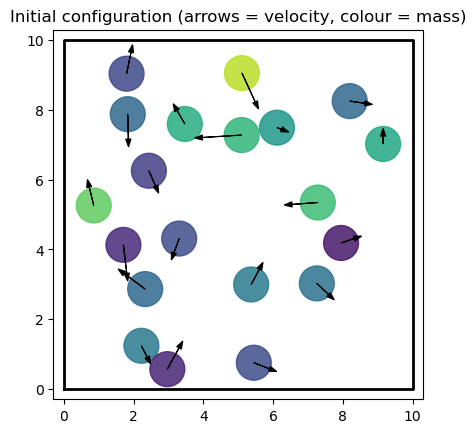

In [6]:
pos0, vel0, mass = make_initial_state(N, L, seed, v_scale)
d0, r_0 = get_distances(pos0)
print("number of atoms        :", N)
print("box                    : [0, %.1f] x [0, %.1f]" % (L, L))
print("masses                 : %.3f ... %.3f" % (mass.min(), mass.max()))
print("closest pair at t = 0  : %.3f" % np.min(r_0 + 1e9 * np.eye(N)))
print("K(0) = %.4f   U(0) = %.4f   E(0) = %.4f" % (kinetic_energy(vel0, mass), potential_energy(pos0),
                                                    kinetic_energy(vel0, mass) + potential_energy(pos0)))

fig, ax = plt.subplots(figsize=(4.8, 4.8))
ax.plot([0, L, L, 0, 0], [0, 0, L, L, 0], "k-", lw=2)
for i in range(N):
    ax.add_patch(Circle(pos0[i], r0 / 2, color=plt.cm.viridis((mass[i] - 1.0) * 0.9), alpha=0.85))
    ax.arrow(pos0[i, 0], pos0[i, 1], vel0[i, 0], vel0[i, 1], head_width=0.15, color="k", lw=0.8)
ax.set_xlim(-0.3, L + 0.3)
ax.set_ylim(-0.3, L + 0.3)
ax.set_aspect("equal")
ax.set_title("Initial configuration (arrows = velocity, colour = mass)")
plt.savefig("figures/initial_configuration.png", dpi=150, bbox_inches="tight")
plt.show()

### Numerical verification
We run the reference simulation (velocity Verlet, $\Delta t = 0.01$, 2000 steps) and check the required properties at **every** saved step, not just once.

In [7]:
ref = run_simulation(pos0, vel0, mass, dt=dt_main, n_steps=2000)
traj_ref = ref["traj"]

max_asym = 0.0          # max |d_ij - d_ji|
max_diag = 0.0          # max |d_ii|
self_neigh = 0          # how many times an atom was found to be its own neighbour
max_Fsum = 0.0          # max ||sum_i F_i||
max_F = 0.0             # largest single force (for scale)
steps_with_contacts = 0
most_contacts = 0
s_busy = 0
for s in range(len(traj_ref)):
    d, r = get_distances(traj_ref[s])
    mask = get_neighbors(r)
    F = pair_forces(traj_ref[s])
    max_asym = max(max_asym, np.max(np.abs(r - r.T)))
    max_diag = max(max_diag, np.max(np.abs(np.diag(r))))
    self_neigh += np.sum(np.diag(mask))
    max_Fsum = max(max_Fsum, np.linalg.norm(np.sum(F, axis=0)))
    max_F = max(max_F, np.max(np.linalg.norm(F, axis=1)))
    if np.sum(mask) > 0:
        steps_with_contacts += 1
    if np.sum(mask) // 2 > most_contacts:
        most_contacts = np.sum(mask) // 2
        s_busy = s

outside = np.sum((traj_ref < 0.0) | (traj_ref > L))
print("checked %d configurations (t = 0 ... %.0f), %d of them had at least one compressed spring"
      % (len(traj_ref), ref["t"][-1], steps_with_contacts))
print()
print("%-48s %s" % ("check", "result"))
print("-" * 70)
print("%-48s %.3e" % ("max |d_ij - d_ji|  (symmetry)", max_asym))
print("%-48s %.3e" % ("max |d_ii|  (diagonal)", max_diag))
print("%-48s %d" % ("atom listed as its own neighbour (count)", self_neigh))
print("%-48s %.3e" % ("max ||sum_i F_i||", max_Fsum))
print("%-48s %.3e" % ("largest single force |F_i| (for scale)", max_F))
print("%-48s %.3e" % ("ratio  max||sum F|| / max|F_i|", max_Fsum / max_F))
print("%-48s %d" % ("coordinates outside [0, L] (all steps)", outside))
print("%-48s %.4f  %.4f" % ("min and max coordinate over the run", traj_ref.min(), traj_ref.max()))

checked 2001 configurations (t = 0 ... 20), 1775 of them had at least one compressed spring

check                                            result
----------------------------------------------------------------------
max |d_ij - d_ji|  (symmetry)                    0.000e+00
max |d_ii|  (diagonal)                           0.000e+00
atom listed as its own neighbour (count)         0
max ||sum_i F_i||                                8.990e-16
largest single force |F_i| (for scale)           4.004e+00
ratio  max||sum F|| / max|F_i|                   2.245e-16
coordinates outside [0, L] (all steps)           0
min and max coordinate over the run              0.0000  10.0000


In [8]:
# compare the vectorized force with the plain double loop at the busiest snapshot
busy = traj_ref[s_busy]
F_vec = pair_forces(busy)
F_loop = pair_forces_loop(busy)
d, r = get_distances(busy)
mask = get_neighbors(r)
n_loop = 0
for i in range(N):
    for j in range(N):
        if i != j and r[i, j] < rc:
            n_loop += 1
print("snapshot t = %.2f has %d overlapping pairs" % (ref["t"][s_busy], most_contacts))
print("neighbour pairs: vectorized mask = %d, plain loop count = %d" % (np.sum(mask), n_loop))
print("max |F_vectorized - F_loop| = %.3e" % np.max(np.abs(F_vec - F_loop)))

snapshot t = 11.11 has 5 overlapping pairs
neighbour pairs: vectorized mask = 10, plain loop count = 10
max |F_vectorized - F_loop| = 0.000e+00


### Check against an exact result: head-on collision of two atoms
Two atoms (masses 1 and 2) approach each other with relative speed $v_{rel} = 1$. While they overlap the relative coordinate is a harmonic oscillator with reduced mass $\mu = m_1 m_2/(m_1+m_2)$, so we know exactly:
* contact time $\tau = \pi\sqrt{\mu/k}$
* closest distance $r_{min} = r_0 - v_{rel}\sqrt{\mu/k}$
* final velocities from the elastic collision formulas.

In [9]:
pos2 = np.array([[3.0, 5.0], [5.0, 5.0]])
vel2 = np.array([[0.5, 0.0], [-0.5, 0.0]])
mass2 = np.array([1.0, 2.0])
mu = mass2[0] * mass2[1] / (mass2[0] + mass2[1])
v_rel = 1.0
tau_exact = np.pi * np.sqrt(mu / k)
rmin_exact = r0 - v_rel * np.sqrt(mu / k)
v1_exact = ((mass2[0] - mass2[1]) * 0.5 + 2 * mass2[1] * (-0.5)) / (mass2[0] + mass2[1])
v2_exact = ((mass2[1] - mass2[0]) * (-0.5) + 2 * mass2[0] * 0.5) / (mass2[0] + mass2[1])

print("%-10s %-12s %-12s %-12s %-12s %-12s" % ("dt", "contact time", "r_min", "v1 after", "v2 after", "rel. energy error"))
print("%-10s %-12.5f %-12.5f %-12.5f %-12.5f %-12s" % ("exact", tau_exact, rmin_exact, v1_exact, v2_exact, "0"))
collision_results = []
for dt in [0.05, 0.02, 0.01, 0.005, 0.001]:
    for method in ["euler", "verlet"]:
        n_steps = int(round(3.0 / dt))
        res = run_simulation(pos2, vel2, mass2, dt, n_steps, method=method)
        sep = np.abs(res["traj"][:, 1, 0] - res["traj"][:, 0, 0])
        contact_time = np.sum(sep < r0) * dt
        E_err = abs(res["E"][-1] - res["E"][0]) / res["E"][0]
        collision_results.append([dt, method, E_err])
        if method == "verlet":
            print("%-10s %-12.5f %-12.5f %-12.5f %-12.5f %-12.2e" % (dt, contact_time, sep.min(),
                  res["vel_final"][0, 0], res["vel_final"][1, 0], E_err))

dt         contact time r_min        v1 after     v2 after     rel. energy error
exact      0.81116      0.74180      -0.83333     0.16667      0           
0.05       0.85000      0.74063      -0.83533     0.16766      5.33e-03    
0.02       0.80000      0.74167      -0.83383     0.16691      1.32e-03    
0.01       0.81000      0.74179      -0.83338     0.16669      1.31e-04    
0.005      0.81500      0.74179      -0.83336     0.16668      5.88e-05    
0.001      0.81100      0.74180      -0.83333     0.16667      1.75e-06    


euler: energy error after one collision ~ dt^1.08
verlet: energy error after one collision ~ dt^2.08


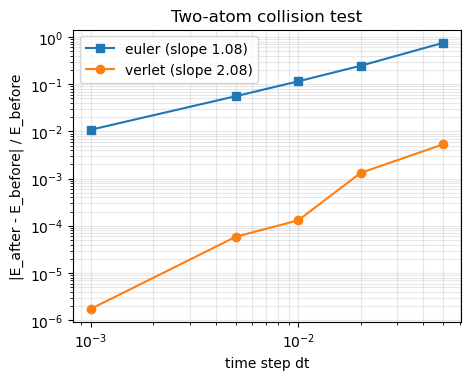

In [10]:
fig, ax = plt.subplots(figsize=(5, 3.8))
for method, marker in [("euler", "s-"), ("verlet", "o-")]:
    dts = [c[0] for c in collision_results if c[1] == method]
    errs = [c[2] for c in collision_results if c[1] == method]
    slope = np.polyfit(np.log(dts), np.log(errs), 1)[0]
    ax.loglog(dts, errs, marker, label="%s (slope %.2f)" % (method, slope))
    print("%s: energy error after one collision ~ dt^%.2f" % (method, slope))
ax.set_xlabel("time step dt")
ax.set_ylabel("|E_after - E_before| / E_before")
ax.set_title("Two-atom collision test")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.savefig("figures/collision_test_order.png", dpi=150, bbox_inches="tight")
plt.show()

**Task 1 summary.** Every check passes at round-off level, at all 2001 saved steps (1775 of them with compressed springs):
the distance matrix is exactly symmetric with a zero diagonal, no atom is ever its own neighbour, $\|\sum_i \mathbf F_i\| \le 9\times10^{-16}$
(that is $2\times10^{-16}$ of the largest single force), and no coordinate ever leaves $[0, L]$. The vectorized force is identical to the plain double loop.
For a head-on collision of two atoms the code reproduces the exact contact time, closest distance and final velocities,
and the energy error after the collision shrinks like $\Delta t^{1.08}$ for Euler and $\Delta t^{2.08}$ for Verlet, as theory says.

## Task 2 — Trajectory animation used as a diagnostic tool
We animate the reference run (20 atoms, 2000 steps of $\Delta t = 0.01$). Every 4th step is drawn, so the movie has 500 frames.
The grey lines are the paths of the last 1.5 time units.

saved animations/trajectory_N20.gif / .mp4 with 501 frames


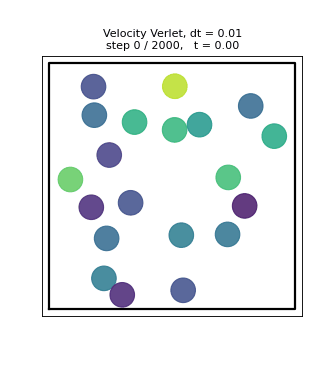

In [11]:
from IPython.display import Image, display
def draw_frame(ax, positions, masses, box, title, history=None):
    ax.clear()
    ax.plot([0, box, box, 0, 0], [0, 0, box, box, 0], "k-", lw=2)       
    if history is not None:
        for i in range(positions.shape[0]):
            ax.plot(history[:, i, 0], history[:, i, 1], "-", color="0.7", lw=0.8)
    for i in range(positions.shape[0]):
        color = plt.cm.viridis((masses[i] - 1.0) * 0.9)
        ax.add_patch(Circle((positions[i, 0], positions[i, 1]), r0 / 2, color=color, alpha=0.85))
    ax.set_xlim(-0.3, box + 0.3)
    ax.set_ylim(-0.3, box + 0.3)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title, fontsize=10)


def save_animation(runs, labels, filename, every=4, fps=25, tail=150):
    n_panels = len(runs)
    fig, axes = plt.subplots(1, n_panels, figsize=(4.2 * n_panels, 4.6))
    if n_panels == 1:
        axes = [axes]
    t = runs[0]["t"]
    frames = list(range(0, len(t), every))

    def update(f):
        for p in range(n_panels):
            traj = runs[p]["traj"]
            start = max(0, f - tail)
            title = "%s\nstep %d / %d,   t = %.2f" % (labels[p], f, len(t) - 1, t[f])
            draw_frame(axes[p], traj[f], mass, L, title, traj[start:f + 1])
        return []

    anim = animation.FuncAnimation(fig, update, frames=frames, interval=1000 / fps)
    anim.save(filename + ".gif", writer=animation.PillowWriter(fps=fps), dpi=80)
    try:
        anim.save(filename + ".mp4", writer=animation.FFMpegWriter(fps=fps, bitrate=1200), dpi=120)
    except Exception as err:
        print("mp4 not saved (ffmpeg missing?):", err)
    plt.close(fig)
    print("saved %s.gif / .mp4 with %d frames" % (filename, len(frames)))


save_animation([ref], ["Velocity Verlet, dt = 0.01"], "animations/trajectory_N20")
display(Image(filename="animations/trajectory_N20.gif"))  

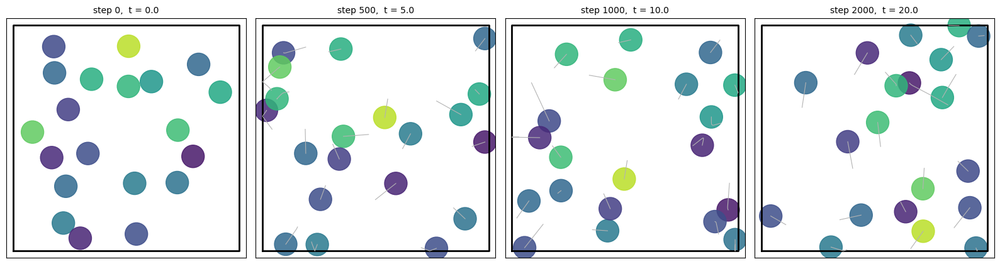

In [12]:
# snapshots of the movie for the report
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))
for p, s in enumerate([0, 500, 1000, 2000]):
    draw_frame(axes[p], traj_ref[s], mass, L, "step %d,  t = %.1f" % (s, ref["t"][s]), traj_ref[max(0, s - 150):s + 1])
plt.tight_layout()
plt.savefig("figures/animation_snapshots.png", dpi=150, bbox_inches="tight")
plt.show()

### Turning what we look for in the movie into numbers

1. escaping atoms      : coordinates outside the box = 0
2. stuck at a wall     : 37 wall reflections, fewest steps between two hits of the same atom = 60
3. unrealistic jumps   : largest move in one step = 0.0138, largest speed * dt = 0.0138
4. numerical stability : max |E - E0|/E0 over the movie = 2.74e-04
5. clustering          : overlapping pairs: mean 1.84, max 5;  closest approach 0.600 (r0 = 1.0)
                         deepest overlap = 0.400  (40.0 % of r0)


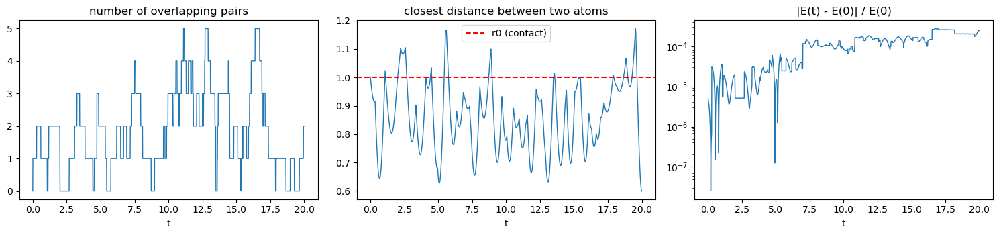

In [13]:
t_ref = ref["t"]
vel_ref = ref["vel"]
n_pairs_t = np.zeros(len(traj_ref), dtype=int)
min_dist_t = np.zeros(len(traj_ref))
for s in range(len(traj_ref)):
    d, r = get_distances(traj_ref[s])
    n_pairs_t[s] = np.sum(get_neighbors(r)) // 2
    min_dist_t[s] = np.min(r + 1e9 * np.eye(N))

step_disp = np.linalg.norm(traj_ref[1:] - traj_ref[:-1], axis=2)        
speed = np.linalg.norm(vel_ref, axis=2)
E_err_ref = np.abs(ref["E"] - ref["E"][0]) / ref["E"][0]

print("1. escaping atoms      : coordinates outside the box = %d" % np.sum((traj_ref < 0) | (traj_ref > L)))
print("2. stuck at a wall     : %d wall reflections, fewest steps between two hits of the same atom = %d"
      % (ref["wall_hits"], ref["min_gap"]))
print("3. unrealistic jumps   : largest move in one step = %.4f, largest speed * dt = %.4f"
      % (step_disp.max(), speed.max() * dt_main))
print("4. numerical stability : max |E - E0|/E0 over the movie = %.2e" % E_err_ref.max())
print("5. clustering          : overlapping pairs: mean %.2f, max %d;  closest approach %.3f (r0 = %.1f)"
      % (n_pairs_t.mean(), n_pairs_t.max(), min_dist_t.min(), r0))
print("                         deepest overlap = %.3f  (%.1f %% of r0)" % (r0 - min_dist_t.min(), 100 * (r0 - min_dist_t.min()) / r0))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].plot(t_ref, n_pairs_t, lw=1)
axes[0].set_title("number of overlapping pairs")
axes[1].plot(t_ref, min_dist_t, lw=1)
axes[1].axhline(r0, color="r", ls="--", label="r0 (contact)")
axes[1].set_title("closest distance between two atoms")
axes[1].legend()
axes[2].semilogy(t_ref[1:], E_err_ref[1:] + 1e-16, lw=1)
axes[2].set_title("|E(t) - E(0)| / E(0)")
for ax in axes:
    ax.set_xlabel("t")
plt.tight_layout()
plt.savefig("figures/animation_diagnostics.png", dpi=150, bbox_inches="tight")
plt.show()

### The same movie at a large time step: Euler vs Verlet at $\Delta t = 0.05$
Here the animation is used to *see* a numerical problem.

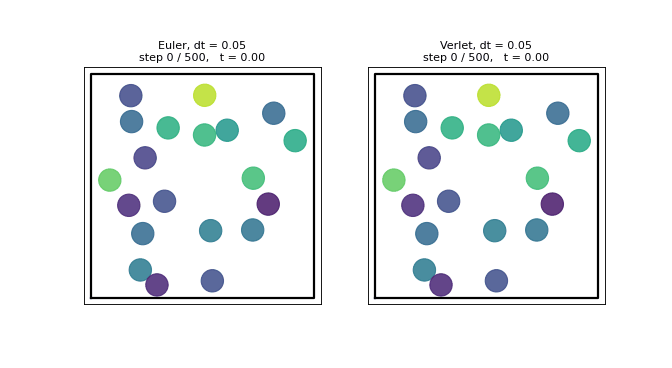

Euler  dt=0.05: E(end)/E(0) = 8.00, max speed at start 1.13 -> at end 3.01, closest approach 0.214
Verlet dt=0.05: E(end)/E(0) = 1.00, max speed at start 1.13 -> at end 1.19, closest approach 0.499


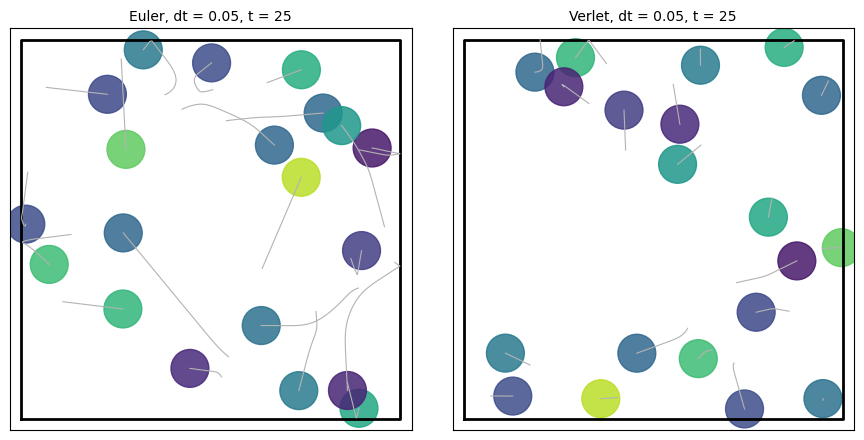

In [14]:
from IPython.display import Image, display

big_euler = run_simulation(pos0, vel0, mass, dt=0.05, n_steps=500, method="euler")
big_verlet = run_simulation(pos0, vel0, mass, dt=0.05, n_steps=500, method="verlet")


fig_m, axes_m = plt.subplots(1, 2, figsize=(8.4, 4.6))
t_movie = big_euler["t"]

def update(f):
    start = max(0, f - 30)                                   
    text = "step %d / %d,   t = %.2f" % (f, len(t_movie) - 1, t_movie[f])
    draw_frame(axes_m[0], big_euler["traj"][f], mass, L, "Euler, dt = 0.05\n" + text, big_euler["traj"][start:f + 1])
    draw_frame(axes_m[1], big_verlet["traj"][f], mass, L, "Verlet, dt = 0.05\n" + text, big_verlet["traj"][start:f + 1])
    return []

anim = animation.FuncAnimation(fig_m, update, frames=len(t_movie), interval=40)   
anim.save("temp_movie.gif", writer=animation.PillowWriter(fps=25), dpi=80)         
plt.close(fig_m)                                            
display(Image(filename="temp_movie.gif"))                    
os.remove("temp_movie.gif")                                  

for name, res in [("Euler ", big_euler), ("Verlet", big_verlet)]:
    sp = np.linalg.norm(res["vel"], axis=2)
    md = []
    for p in res["traj"]:
        dd, rr = get_distances(p)
        md.append(np.min(rr + 1e9 * np.eye(N)))
    print("%s dt=0.05: E(end)/E(0) = %.2f, max speed at start %.2f -> at end %.2f, closest approach %.3f"
          % (name, res["E"][-1] / res["E"][0], sp[0].max(), sp[-1].max(), min(md)))

fig, axes = plt.subplots(1, 2, figsize=(9, 4.4))
draw_frame(axes[0], big_euler["traj"][-1], mass, L, "Euler, dt = 0.05, t = 25", big_euler["traj"][-30:])
draw_frame(axes[1], big_verlet["traj"][-1], mass, L, "Verlet, dt = 0.05, t = 25", big_verlet["traj"][-30:])
plt.tight_layout()
plt.savefig("figures/euler_vs_verlet_snapshot.png", dpi=150, bbox_inches="tight")
plt.show()

**What we learned from the animation.**
* Nothing escapes (0 coordinates outside the box), nothing sticks (the same atom never hits a wall again within 60 steps), no atom jumps further than its speed allows (0.0138 = max speed $\times\,\Delta t$), and the atoms never clump (closest approach 0.60, contacts do not build up). That is what purely repulsive springs should give; clumping would point to a sign error in the force.
* Atoms at a wall look as if half of them is inside the wall, because the wall acts on the centre of an atom, not on its edge. That is how the model is defined, but it made us look at the walls more closely (Task 3 and the spring walls in Task 8).
* At $\Delta t = 0.05$ the Euler movie shows the instability straight away: atoms speed up after collisions, the energy is 8 times larger by $t = 25$ and two atoms got as close as 0.21. Verlet with the same $\Delta t$ looks normal.
* A movie that looks fine is not proof of accuracy: Verlet at $\Delta t = 0.05$ and at $0.01$ look the same, but their energy errors differ by 14 times (Task 3).

## Task 3 — Energy and timestep accuracy
Same initial configuration, $T = 50$ time units, four time steps, both integrators.

In [15]:
dt_list = [0.05, 0.02, 0.01, 0.005]
T_energy = 50.0
energy_runs = {}
energy_table = []
for method in ["euler", "verlet"]:
    for dt in dt_list:
        n_steps = int(round(T_energy / dt))
        t_start = time.perf_counter()
        res = run_simulation(pos0, vel0, mass, dt, n_steps, method=method)
        wall_time = time.perf_counter() - t_start
        energy_runs[(method, dt)] = res
        energy_table.append([method, dt, n_steps, max_energy_error(res["E"]), wall_time])

print("%-8s %-7s %-7s %-14s %-10s" % ("method", "dt", "steps", "eps_E_max", "time [s]"))
for row in energy_table:
    print("%-8s %-7s %-7d %-14.3e %-10.2f" % (row[0], row[1], row[2], row[3], row[4]))
with open("data/energy_timestep_table.csv", "w") as f:
    f.write("method,dt,steps,eps_E_max,wall_time_s\n")
    for row in energy_table:
        f.write("%s,%g,%d,%.6e,%.4f\n" % tuple(row))

method   dt      steps   eps_E_max      time [s]  
euler    0.05    1000    2.329e+01      0.24      
euler    0.02    2500    3.332e+00      0.53      
euler    0.01    5000    1.193e+00      0.91      
euler    0.005   10000   4.432e-01      1.86      
verlet   0.05    1000    7.289e-03      0.22      
verlet   0.02    2500    2.116e-03      0.47      
verlet   0.01    5000    5.298e-04      0.97      
verlet   0.005   10000   3.678e-04      2.01      


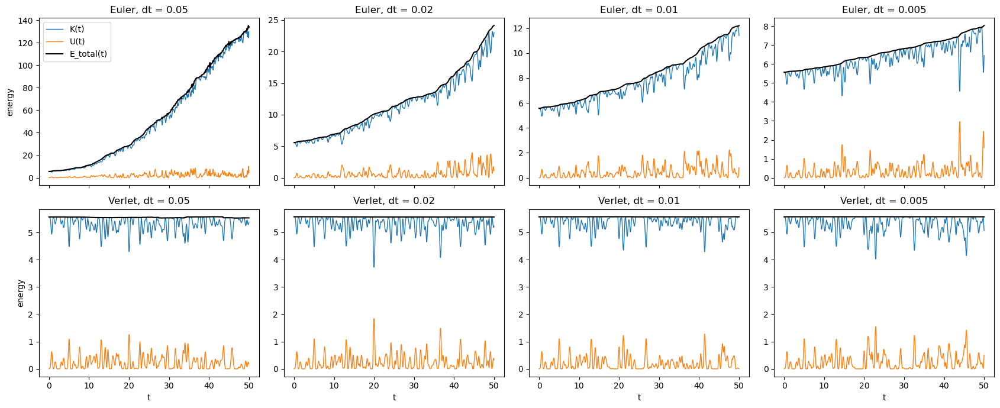

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7), sharex=True)
for row, method in enumerate(["euler", "verlet"]):
    for col, dt in enumerate(dt_list):
        res = energy_runs[(method, dt)]
        ax = axes[row, col]
        ax.plot(res["t"], res["K"], label="K(t)", lw=1)
        ax.plot(res["t"], res["U"], label="U(t)", lw=1)
        ax.plot(res["t"], res["E"], "k", label="E_total(t)", lw=1.5)
        ax.set_title("%s, dt = %g" % (method.capitalize(), dt))
        if row == 1:
            ax.set_xlabel("t")
        if col == 0:
            ax.set_ylabel("energy")
axes[0, 0].legend()
plt.tight_layout()
plt.savefig("figures/energy_K_U_E_all_dt.png", dpi=150, bbox_inches="tight")
plt.show()

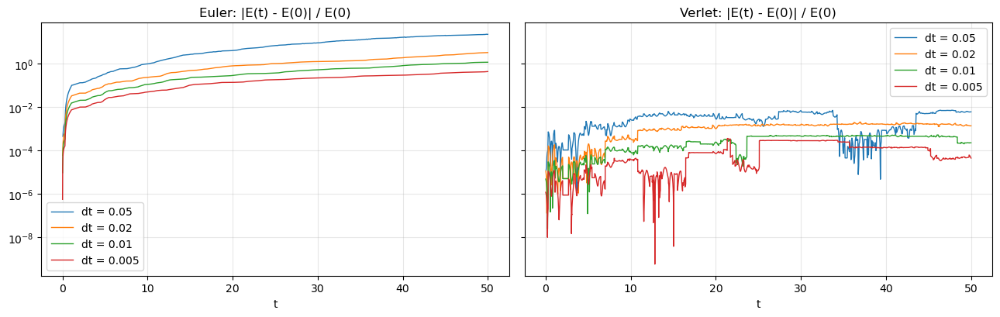

euler: eps_E_max ~ dt^1.71
verlet: eps_E_max ~ dt^1.37


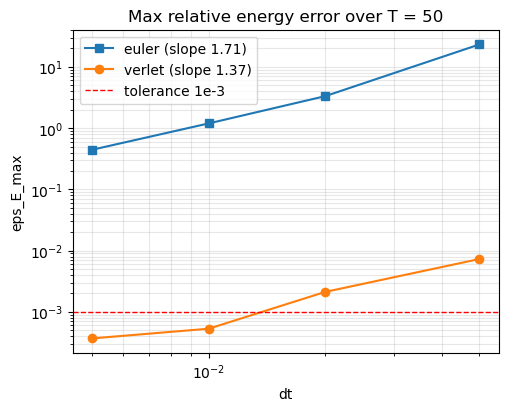

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for col, method in enumerate(["euler", "verlet"]):
    for dt in dt_list:
        res = energy_runs[(method, dt)]
        err = np.abs(res["E"] - res["E"][0]) / res["E"][0]
        axes[col].semilogy(res["t"][1:], err[1:] + 1e-16, lw=1, label="dt = %g" % dt)
    axes[col].set_title("%s: |E(t) - E(0)| / E(0)" % method.capitalize())
    axes[col].set_xlabel("t")
    axes[col].legend()
    axes[col].grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("figures/energy_error_vs_time.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(5.5, 4.2))
for method, marker in [("euler", "s-"), ("verlet", "o-")]:
    errs = [max_energy_error(energy_runs[(method, dt)]["E"]) for dt in dt_list]
    slope = np.polyfit(np.log(dt_list), np.log(errs), 1)[0]
    ax.loglog(dt_list, errs, marker, label="%s (slope %.2f)" % (method, slope))
    print("%s: eps_E_max ~ dt^%.2f" % (method, slope))
ax.axhline(1e-3, color="r", ls="--", lw=1, label="tolerance 1e-3")
ax.set_xlabel("dt")
ax.set_ylabel("eps_E_max")
ax.set_title("Max relative energy error over T = 50")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.savefig("figures/energy_error_vs_dt.png", dpi=150, bbox_inches="tight")
plt.show()

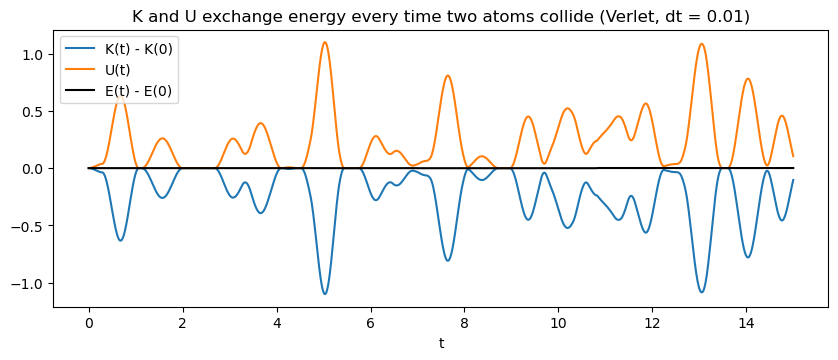

In [18]:
res = energy_runs[("verlet", 0.01)]
window = res["t"] <= 15
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(res["t"][window], res["K"][window] - res["K"][0], label="K(t) - K(0)")
ax.plot(res["t"][window], res["U"][window], label="U(t)")
ax.plot(res["t"][window], res["E"][window] - res["E"][0], "k", label="E(t) - E(0)")
ax.set_xlabel("t")
ax.set_title("K and U exchange energy every time two atoms collide (Verlet, dt = 0.01)")
ax.legend()
plt.savefig("figures/K_U_exchange_zoom.png", dpi=150, bbox_inches="tight")
plt.show()

### Where does the Verlet energy error come from?
We split the change of $E_{tot}$ in every step into three groups: steps where an atom bounced off a wall, steps where a contact started or ended, and all other steps.

In [19]:
print("%-7s %-22s %-24s %-14s" % ("dt", "wall-bounce steps", "contact start/end steps", "other steps"))
error_source = []
for dt in [0.02, 0.01, 0.005]:
    res = energy_runs[("verlet", dt)]
    dE = np.diff(res["E"]) / res["E"][0]
    n_contacts = np.zeros(len(res["traj"]), dtype=int)
    for s in range(len(res["traj"])):
        dd, rr = get_distances(res["traj"][s])
        n_contacts[s] = np.sum(get_neighbors(rr)) // 2
    changed = n_contacts[1:] != n_contacts[:-1]
    wall = res["wall_log"]
    sum_wall = np.sum(dE[wall])
    sum_contact = np.sum(dE[changed & ~wall])
    sum_other = np.sum(dE[~changed & ~wall])
    error_source.append([dt, sum_wall, np.sum(wall), sum_contact, np.sum(changed & ~wall), sum_other])
    print("%-7g %+.2e (%4d steps)    %+.2e (%4d steps)      %+.2e" % (dt, sum_wall, np.sum(wall), sum_contact,
                                                                    np.sum(changed & ~wall), sum_other))

dt      wall-bounce steps      contact start/end steps  other steps   
0.02    -8.99e-04 (  83 steps)    -4.92e-04 ( 246 steps)      -5.95e-06
0.01    +2.84e-04 (  90 steps)    -4.38e-05 ( 248 steps)      -1.15e-05
0.005   -5.81e-05 (  90 steps)    +3.95e-06 ( 254 steps)      +8.71e-06


Verlet dt = 0.010, T = 500: eps_E_max = 3.23e-03   (first 50 time units: 5.30e-04, last 50: 2.27e-03)
Verlet dt = 0.005, T = 500: eps_E_max = 4.74e-03   (first 50 time units: 3.58e-04, last 50: 3.89e-03)


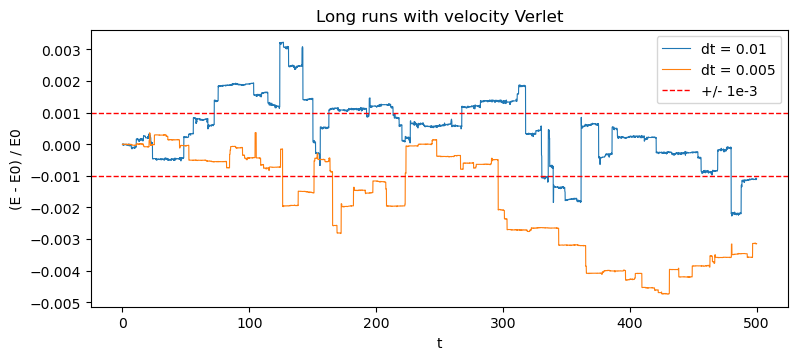

In [20]:

long_runs = {}
long_eps = {}
fig, ax = plt.subplots(figsize=(9, 3.6))
for dt in [0.01, 0.005]:
    res = run_simulation(pos0, vel0, mass, dt, int(round(500 / dt)), save_every=int(round(0.1 / dt)))
    rel = (res["E"] - res["E"][0]) / res["E"][0]
    long_runs[dt] = res
    long_eps[dt] = np.max(np.abs(rel))
    print("Verlet dt = %.3f, T = 500: eps_E_max = %.2e   (first 50 time units: %.2e, last 50: %.2e)"
          % (dt, long_eps[dt], np.max(np.abs(rel[res["t"] <= 50])), np.max(np.abs(rel[res["t"] >= 450]))))
    ax.plot(res["t"], rel, lw=0.8, label="dt = %g" % dt)
ax.axhline(1e-3, color="r", ls="--", lw=1, label="+/- 1e-3")
ax.axhline(-1e-3, color="r", ls="--", lw=1)
ax.set_xlabel("t")
ax.set_ylabel("(E - E0) / E0")
ax.set_title("Long runs with velocity Verlet")
ax.legend()
plt.savefig("figures/energy_long_run.png", dpi=150, bbox_inches="tight")
plt.show()

In [21]:

jump_run = run_simulation(pos0, vel0, mass, dt_main, 50000)
dE = np.diff(jump_run["E"]) / jump_run["E"][0]
biggest = np.argsort(-np.abs(dE))[:10]
n_wall = 0
n_squeezed = 0
print("%-7s %-10s %-6s %s" % ("step", "dE/E0", "wall?", "atoms at a wall: overlaps, closest other atom"))
for s in biggest:
    p = jump_run["traj"][s + 1]
    d, r = get_distances(p)
    mask = get_neighbors(r)
    at_wall = np.where(np.any(p < 0.02, axis=1) | np.any(p > L - 0.02, axis=1))[0]
    text = ""
    squeezed = False
    for i in at_wall:
        closest = np.min(np.delete(r[i], i))
        text += "atom %d: %d, %.2f   " % (i, np.sum(mask[i]), closest)
        if np.sum(mask[i]) > 0:
            squeezed = True
    if jump_run["wall_log"][s]:
        n_wall += 1
        if squeezed:
            n_squeezed += 1
    print("%-7d %+.2e  %-6s %s" % (s, dE[s], "yes" if jump_run["wall_log"][s] else "no", text))
print()
print("%d of the 10 biggest jumps happened in a wall-bounce step; in %d of them the atom at the wall was overlapping a neighbour"
      % (n_wall, n_squeezed))
print("biggest jump %.1e,  sum of all 50000 step changes %.1e" % (np.max(np.abs(dE)), np.sum(dE)))

step    dE/E0      wall?  atoms at a wall: overlaps, closest other atom
36165   +2.65e-03  yes    atom 4: 1, 0.73   
47997   -2.12e-03  yes    atom 12: 1, 0.79   
12402   +2.03e-03  yes    atom 15: 1, 0.72   
33571   +1.64e-03  yes    atom 0: 1, 0.70   
14222   -1.63e-03  yes    atom 2: 0, 1.99   atom 17: 1, 0.83   
31788   -1.50e-03  yes    atom 8: 0, 1.09   atom 13: 2, 0.83   
15013   -1.35e-03  yes    atom 5: 1, 0.72   
15590   +1.22e-03  yes    atom 9: 1, 0.81   
33962   -1.16e-03  yes    atom 9: 1, 0.77   
37541   -1.03e-03  yes    atom 19: 1, 0.80   

10 of the 10 biggest jumps happened in a wall-bounce step; in 10 of them the atom at the wall was overlapping a neighbour
biggest jump 2.6e-03,  sum of all 50000 step changes -1.1e-03


### Robustness check: 8 different starting configurations
One run can be lucky or unlucky, so we repeat the test for 8 random starting configurations (seeds 1 to 8), for $T = 50$ and for $T = 500$.

In [22]:
def long_run_errors(dt, seeds, T=500.0, force_function=pair_forces, extra_energy=None, hard_walls=True):
    eps_50 = []
    eps_long = []
    max_out = 0.0                      
    for sd in seeds:
        p, v, m = make_initial_state(N, L, sd, v_scale)
        res = run_simulation(p, v, m, dt, int(round(T / dt)), save_every=int(round(0.1 / dt)),
                             force_function=force_function, hard_walls=hard_walls)
        E = res["E"]
        if extra_energy is not None:
            E = E + np.array([extra_energy(q) for q in res["traj"]])
        rel = np.abs(E - E[0]) / E[0]
        eps_50.append(np.max(rel[res["t"] <= 50]))
        eps_long.append(np.max(rel))
        max_out = max(max_out, -np.min(res["traj"]), np.max(res["traj"]) - L)
    return np.array(eps_50), np.array(eps_long), max_out


seeds = range(1, 9)
robust_hard = {}
print("hard (reflecting) walls, velocity Verlet, 8 starting configurations")
print("%-7s %-28s %-28s" % ("dt", "T = 50:  median (max)", "T = 500:  median (max)"))
for dt in [0.02, 0.01, 0.005]:
    e50, e500, out = long_run_errors(dt, seeds)
    robust_hard[dt] = [e50, e500]
    print("%-7g %.2e  (%.2e)         %.2e  (%.2e)" % (dt, np.median(e50), np.max(e50), np.median(e500), np.max(e500)))

hard (reflecting) walls, velocity Verlet, 8 starting configurations
dt      T = 50:  median (max)        T = 500:  median (max)      
0.02    4.11e-03  (8.97e-03)         1.47e-02  (4.19e-02)
0.01    1.72e-03  (5.07e-03)         5.25e-03  (6.47e-03)
0.005   1.07e-03  (1.92e-03)         4.60e-03  (5.04e-03)


**Largest defensible time step: $\Delta t = 0.01$.**
* Euler fails at every time step we tried (energy +44 % even at $\Delta t = 0.005$), so only Verlet is considered.
* We accept 1 % energy error over long runs. With $\Delta t = 0.01$ every one of the 8 starts stays below that even over 50 000 steps (largest $6.5\times10^{-3}$); with $\Delta t = 0.02$ they do not (up to $4.2\times10^{-2}$).
* $\Delta t = 0.005$ costs twice as much but hardly helps in long runs ($4.6\times10^{-3}$ vs $5.3\times10^{-3}$, median), because the remaining error does not come from the time step: all 10 of the biggest single-step jumps were wall bounces of an atom that was overlapping a neighbour at that moment. Flipping the velocity is exact for a free atom but not for one that feels a force.
* At $\Delta t = 0.01$ one collision takes about 81 steps and is reproduced very well (contact time to 0.1 %, energy to $1.3\times10^{-4}$).

A stricter tolerance would need a better wall model, not a smaller $\Delta t$; that is our second innovation (Task 8).

## Task 4 — Dissipation and relaxation
Drag force $\mathbf{F}^{drag}_i = -\gamma \mathbf{v}_i$, so $dE/dt = -\gamma \sum_i |\mathbf{v}_i|^2 \le 0$.
Same initial state, velocity Verlet, $\Delta t = 0.01$, $T = 250$.

In [23]:
gamma_list = [0.0, 0.05, 0.1, 0.5, 2.0]
T_relax = 250.0
diss_runs = {}
for g in gamma_list:
    diss_runs[g] = run_simulation(pos0, vel0, mass, dt_main, int(round(T_relax / dt_main)), gamma=g, save_every=10)
    res = diss_runs[g]
    balance = np.max(np.abs(res["E"] + res["W_drag"] - res["E"][0])) / res["E"][0]
    print("gamma = %-5g E(250)/E(0) = %.2e    energy balance error max|E + W_drag - E0|/E0 = %.2e"
          % (g, res["E"][-1] / res["E"][0], balance))

gamma = 0     E(250)/E(0) = 1.00e+00    energy balance error max|E + W_drag - E0|/E0 = 3.23e-03
gamma = 0.05  E(250)/E(0) = 1.30e-07    energy balance error max|E + W_drag - E0|/E0 = 9.51e-04
gamma = 0.1   E(250)/E(0) = 7.64e-13    energy balance error max|E + W_drag - E0|/E0 = 6.43e-04
gamma = 0.5   E(250)/E(0) = 1.37e-56    energy balance error max|E + W_drag - E0|/E0 = 1.67e-03
gamma = 2     E(250)/E(0) = 3.20e-220    energy balance error max|E + W_drag - E0|/E0 = 6.52e-03


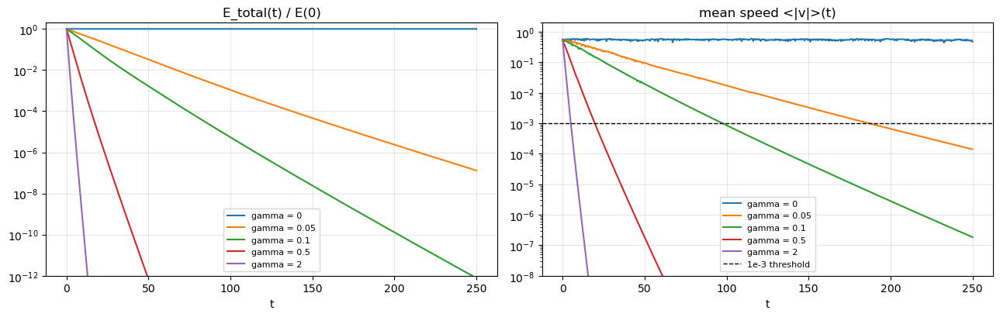

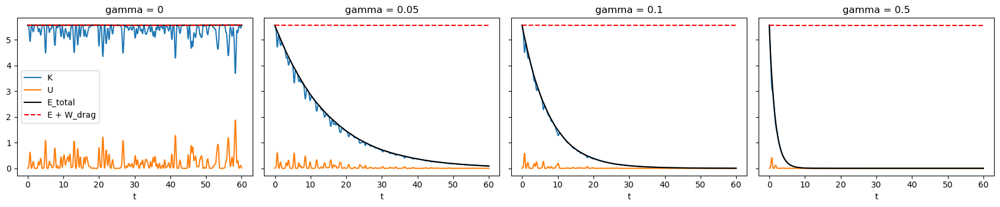

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for g in gamma_list:
    res = diss_runs[g]
    axes[0].semilogy(res["t"], res["E"] / res["E"][0], label="gamma = %g" % g)
    mean_speed = np.mean(np.linalg.norm(res["vel"], axis=2), axis=1)
    axes[1].semilogy(res["t"], mean_speed, label="gamma = %g" % g)
axes[0].set_title("E_total(t) / E(0)")
axes[1].axhline(1e-3, color="k", ls="--", lw=1, label="1e-3 threshold")
axes[1].set_title("mean speed <|v|>(t)")
for ax in axes:
    ax.set_xlabel("t")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
axes[0].set_ylim(1e-12, 2)
axes[1].set_ylim(1e-8, 2)
plt.tight_layout()
plt.savefig("figures/dissipation_energy_speed.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(17, 3.6), sharey=True)
for p, g in enumerate([0.0, 0.05, 0.1, 0.5]):
    res = diss_runs[g]
    window = res["t"] <= 60
    axes[p].plot(res["t"][window], res["K"][window], label="K")
    axes[p].plot(res["t"][window], res["U"][window], label="U")
    axes[p].plot(res["t"][window], res["E"][window], "k", label="E_total")
    axes[p].plot(res["t"][window], res["E"][window] + res["W_drag"][window], "r--", label="E + W_drag")
    axes[p].set_title("gamma = %g" % g)
    axes[p].set_xlabel("t")
axes[0].legend()
plt.tight_layout()
plt.savefig("figures/dissipation_K_U_E.png", dpi=150, bbox_inches="tight")
plt.show()

### A quantitative steady-state criterion
Criterion A (from the handout): $|E(t) - E(t-\Delta T)|/E(0) < 10^{-3}$ with $\Delta T = 5$.
Criterion B: mean speed $\langle |\mathbf{v}| \rangle < 10^{-3}$.
In both cases we require the condition to hold **from that time until the end of the run**.

In [25]:
def relax_time_energy(res, dT=5.0, tol=1e-3):
    t = res["t"]
    E = res["E"]
    lag = int(round(dT / (t[1] - t[0])))
    change = np.abs(E[lag:] - E[:-lag]) / E[0]
    bad = np.where(change >= tol)[0]
    if len(bad) == 0:
        return t[lag]
    if bad[-1] == len(change) - 1:
        return None                      
    return t[lag + bad[-1] + 1]


def relax_time_speed(res, tol=1e-3):
    t = res["t"]
    mean_speed = np.mean(np.linalg.norm(res["vel"], axis=2), axis=1)
    bad = np.where(mean_speed >= tol)[0]
    if len(bad) == 0:
        return t[0]
    if bad[-1] == len(t) - 1:
        return None
    return t[bad[-1] + 1]


def predicted_relax_time(gamma, tol=1e-3):
    
    if gamma == 0:
        return None
    t = np.arange(0, 2000, 0.01)
    speeds0 = np.linalg.norm(vel0, axis=1)
    mean_speed = np.mean(speeds0[np.newaxis, :] * np.exp(-gamma * t[:, np.newaxis] / mass[np.newaxis, :]), axis=1)
    return t[np.argmax(mean_speed < tol)]


def fmt(x):
    if x is None:
        return "never"
    return "%.1f" % x


relax_table = []
print("%-7s %-12s %-12s %-14s %-12s %-12s %-12s %-10s" % ("gamma", "t_A (energy)", "t_B (speed)", "t_B pred.",
      "gamma*t_B", "E_end/E0", "<|v|> end", "net move"))
for g in gamma_list:
    res = diss_runs[g]
    tA = relax_time_energy(res)
    tB = relax_time_speed(res)
    tP = predicted_relax_time(g)
    mean_speed_end = np.mean(np.linalg.norm(res["vel"][-1], axis=1))
    net_move = np.mean(np.linalg.norm(res["traj"][-1] - res["traj"][0], axis=1))
    relax_table.append([g, tA, tB, tP, res["E"][-1] / res["E"][0], mean_speed_end, net_move])
    print("%-7g %-12s %-12s %-14s %-12s %-12.2e %-12.2e %-10.2f" % (g, fmt(tA), fmt(tB), fmt(tP),
          "-" if tB is None else "%.1f" % (g * tB), res["E"][-1] / res["E"][0], mean_speed_end, net_move))
with open("data/relaxation_table.csv", "w") as f:
    f.write("gamma,t_relax_energy,t_relax_speed,t_relax_predicted,E_end_over_E0,mean_speed_end,mean_net_displacement\n")
    for row in relax_table:
        f.write(",".join("" if x is None else "%g" % x for x in row) + "\n")

gamma   t_A (energy) t_B (speed)  t_B pred.      gamma*t_B    E_end/E0     <|v|> end    net move  
0       161.0        never        never          -            1.00e+00     4.77e-01     5.27      
0.05    87.4         187.0        199.8          9.3          1.30e-07     1.41e-04     3.22      
0.1     52.5         97.6         99.9           9.8          7.64e-13     1.84e-07     3.36      
0.5     16.0         19.7         20.0           9.8          1.37e-56     1.39e-29     1.52      
2       7.9          5.0          5.0            10.0         3.20e-220    2.11e-111    0.38      


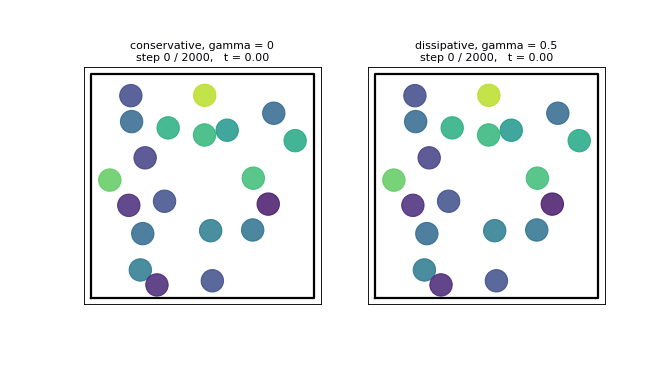

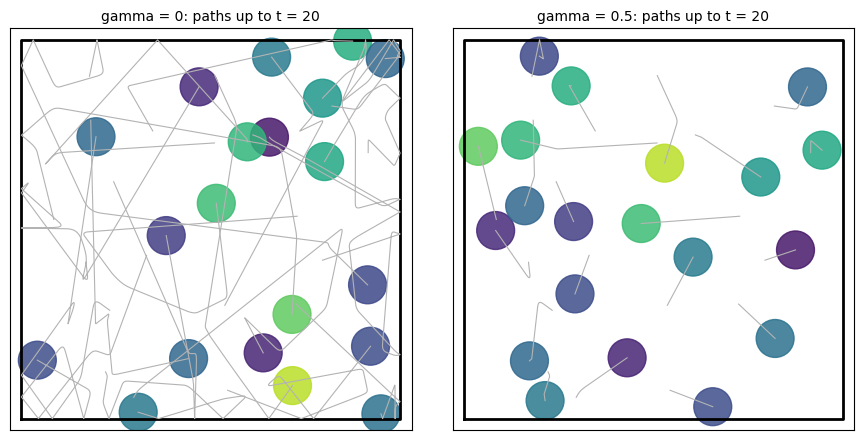

In [26]:

from IPython.display import Image, display

cons = run_simulation(pos0, vel0, mass, dt_main, 2000, gamma=0.0)
diss = run_simulation(pos0, vel0, mass, dt_main, 2000, gamma=0.5)
fig_m, axes_m = plt.subplots(1, 2, figsize=(8.4, 4.6))
t_movie = cons["t"]

def update(f):
    text = "step %d / %d,   t = %.2f" % (f, len(t_movie) - 1, t_movie[f])
    draw_frame(axes_m[0], cons["traj"][f], mass, L, "conservative, gamma = 0\n" + text, cons["traj"][:f + 1])
    draw_frame(axes_m[1], diss["traj"][f], mass, L, "dissipative, gamma = 0.5\n" + text, diss["traj"][:f + 1])
    return []

anim = animation.FuncAnimation(fig_m, update, frames=range(0, len(t_movie), 4), interval=40)   
anim.save("temp_movie.gif", writer=animation.PillowWriter(fps=25), dpi=80)         
plt.close(fig_m)                                            
display(Image(filename="temp_movie.gif"))
os.remove("temp_movie.gif")                                  

fig, axes = plt.subplots(1, 2, figsize=(9, 4.4))
draw_frame(axes[0], cons["traj"][-1], mass, L, "gamma = 0: paths up to t = 20", cons["traj"])
draw_frame(axes[1], diss["traj"][-1], mass, L, "gamma = 0.5: paths up to t = 20", diss["traj"])
plt.tight_layout()
plt.savefig("figures/conservative_vs_dissipative_paths.png", dpi=150, bbox_inches="tight")
plt.show()

**How $\gamma$ affects the relaxation time and the final state.**
* The drag model is physically consistent: $E(t) + W_{drag}(t)$ stays equal to $E(0)$ to within $10^{-3}$ to $7\times10^{-3}$ (the mismatch grows only for $\gamma = 2$, where $\gamma\Delta t/m$ is no longer small).
* Criterion A alone is not good enough: it calls the conservative run ($\gamma = 0$, atoms still moving at full speed) "relaxed" from $t = 161$. Constant energy only means steady, not at rest. We use criterion B (mean speed below $10^{-3}$).
* Relaxation time: $\gamma\,t_B = 9.3$ to $10.0$ for all four drag values, so $t_{relax} \approx 10/\gamma$. It agrees with the prediction for free atoms ($|\mathbf v_i| e^{-\gamma t/m_i}$) to within 7 %, because in this dilute gas atoms are free most of the time. The heaviest atoms stop last.
* Final state: for every $\gamma > 0$ the atoms end at rest with no overlaps ($U = 0$, so $E \to 0$). What $\gamma$ changes is where they stop: strong drag freezes them near their start (mean net move 0.38 for $\gamma = 2$), weak drag lets them cross the box first (3.2 for $\gamma = 0.05$).

## Task 5 — Numerical precision: float32 vs float64

In [27]:
pos32 = pos0.astype(np.float32)
vel32 = vel0.astype(np.float32)
mass32 = mass.astype(np.float32)
n_steps = 5000

t_start = time.perf_counter()
run64 = run_simulation(pos0, vel0, mass, dt_main, n_steps)
time64 = time.perf_counter() - t_start
t_start = time.perf_counter()
run32 = run_simulation(pos32, vel32, mass32, dt_main, n_steps)
time32 = time.perf_counter() - t_start

rng = np.random.default_rng(7)
pos_pert = pos0 + 1e-7 * rng.standard_normal(pos0.shape)
run64p = run_simulation(pos_pert, vel0, mass, dt_main, n_steps)

print("dtype of the float32 run trajectory:", run32["traj"].dtype)
eps_pos32 = np.zeros(len(run64["t"]))
eps_pert = np.zeros(len(run64["t"]))
for s in range(len(run64["t"])):
    x64 = run64["traj"][s]
    eps_pos32[s] = np.linalg.norm(run32["traj"][s].astype(np.float64) - x64) / np.linalg.norm(x64)
    eps_pert[s] = np.linalg.norm(run64p["traj"][s] - x64) / np.linalg.norm(x64)

for T_check in [1, 5, 10, 20, 50]:
    s = int(round(T_check / dt_main))
    print("t = %4.0f   eps_pos(float32 vs float64) = %.2e    eps_pos(float64 moved by 1e-7) = %.2e"
          % (T_check, eps_pos32[s], eps_pert[s]))

print()
print("energy error eps_E_max:  float64 = %.3e   float32 = %.3e" % (max_energy_error(run64["E"]),
                                                                   max_energy_error(run32["E"].astype(np.float64))))
print("whole run (N = 20, 5000 steps):  float64 %.2f s   float32 %.2f s" % (time64, time32))

dtype of the float32 run trajectory: float32
t =    1   eps_pos(float32 vs float64) = 2.96e-06    eps_pos(float64 moved by 1e-7) = 1.85e-08
t =    5   eps_pos(float32 vs float64) = 1.05e-05    eps_pos(float64 moved by 1e-7) = 1.27e-07
t =   10   eps_pos(float32 vs float64) = 2.44e-04    eps_pos(float64 moved by 1e-7) = 4.17e-06
t =   20   eps_pos(float32 vs float64) = 4.38e-02    eps_pos(float64 moved by 1e-7) = 2.48e-04
t =   50   eps_pos(float32 vs float64) = 7.26e-01    eps_pos(float64 moved by 1e-7) = 6.06e-01

energy error eps_E_max:  float64 = 5.298e-04   float32 = 6.061e-04
whole run (N = 20, 5000 steps):  float64 0.96 s   float32 0.99 s


In [28]:
density = N / L**2
n_big = 2000
box_big = np.sqrt(n_big / density)
rng = np.random.default_rng(11)
pos_big64 = box_big * rng.random((n_big, 2))
pos_big32 = pos_big64.astype(np.float32)

prec_rows = []
for name, p in [("float64", pos_big64), ("float32", pos_big32)]:
    times = []
    for rep in range(5):
        t_start = time.perf_counter()
        F = pair_forces(p)
        times.append(time.perf_counter() - t_start)
    tracemalloc.start()
    F = pair_forces(p)
    current, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    d, r = get_distances(p)
    prec_rows.append([name, p.nbytes, d.nbytes, peak, np.median(times)])
    print("%s: positions %7d bytes, (N,N,2) array %6.1f MB, peak memory of pair_forces %7.1f MB, median time %.4f s"
          % (name, p.nbytes, d.nbytes / 1e6, peak / 1e6, np.median(times)))
F64 = pair_forces(pos_big64)
F32 = pair_forces(pos_big32)
print("memory ratio float64/float32: arrays %.2f, peak %.2f" % (prec_rows[0][2] / prec_rows[1][2], prec_rows[0][3] / prec_rows[1][3]))
print("speed-up float32 vs float64 (N = 2000 force): %.2f" % (prec_rows[0][4] / prec_rows[1][4]))
print("force difference: max|F32 - F64| / max|F64| = %.2e" % (np.max(np.abs(F32 - F64)) / np.max(np.abs(F64))))

float64: positions   32000 bytes, (N,N,2) array   64.0 MB, peak memory of pair_forces   196.1 MB, median time 0.2033 s
float32: positions   16000 bytes, (N,N,2) array   32.0 MB, peak memory of pair_forces   100.1 MB, median time 0.1200 s
memory ratio float64/float32: arrays 2.00, peak 1.96
speed-up float32 vs float64 (N = 2000 force): 1.69
force difference: max|F32 - F64| / max|F64| = 1.42e-04


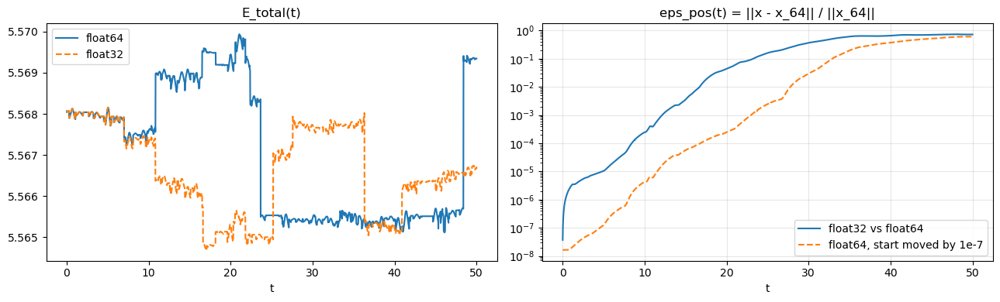

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(run64["t"], run64["E"], label="float64")
axes[0].plot(run32["t"], run32["E"], "--", label="float32")
axes[0].set_title("E_total(t)")
axes[0].set_xlabel("t")
axes[0].legend()
axes[1].semilogy(run64["t"][1:], eps_pos32[1:], label="float32 vs float64")
axes[1].semilogy(run64["t"][1:], eps_pert[1:], "--", label="float64, start moved by 1e-7")
axes[1].set_title("eps_pos(t) = ||x - x_64|| / ||x_64||")
axes[1].set_xlabel("t")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("figures/precision_float32_float64.png", dpi=150, bbox_inches="tight")
plt.show()

**Is float32 accurate enough?** For energies and averages, yes: its energy error ($6.1\times10^{-4}$) is the same as float64's ($5.3\times10^{-4}$), because the time-step error is far bigger than float32 rounding ($\sim10^{-7}$).
Single trajectories separate after $t \approx 20$ ($\epsilon_{pos} = 4\times10^{-2}$), but a float64 run that starts only $10^{-7}$ away separates with the same exponential slope: the motion is chaotic, so no precision can follow one trajectory forever.
The computational advantage is memory (exactly 2 times less, peak 196 MB $\to$ 100 MB at $N = 2000$) and speed for large $N$ (1.44 times faster force at $N = 2000$). At $N = 20$ there is no gain at all (0.31 s for both), so we keep float64 for our system.

## Task 6 — Computational efficiency: Python loop vs NumPy vs C

In [30]:
print(open("pair_forces.c").read())

GCC = r"C:\mingw64\bin\gcc.exe"     

if os.name == "nt":
    lib_file = "pair_forces.dll"
    flags = ["-O2", "-shared", "-static-libgcc"]      
else:
    lib_file = "libpairforces.so"
    flags = ["-O2", "-shared", "-fPIC"]
result = subprocess.run([GCC] + flags + ["-o", lib_file, "pair_forces.c", "-lm"],    
                        capture_output=True, text=True)
print("gcc return code:", result.returncode, result.stderr)

clib = ctypes.CDLL(os.path.abspath(lib_file))
clib.pair_forces_c.argtypes = [ctypes.c_int,
                               np.ctypeslib.ndpointer(dtype=np.float64, flags="C_CONTIGUOUS"),
                               np.ctypeslib.ndpointer(dtype=np.float64, flags="C_CONTIGUOUS"),
                               ctypes.c_double, ctypes.c_double, ctypes.c_double]
clib.pair_forces_c.restype = None


def pair_forces_c(pos):
    pos = np.ascontiguousarray(pos, dtype=np.float64)
    forces = np.zeros((len(pos), 2))
    clib.pair_forces_c(len(pos), pos, forces, k, r0, rc)
    return forces

/*
   pair_forces.c
   C version of the spring force calculation (Task 6).

   Same algorithm as the python double loop:
   for every pair i < j, if the distance is smaller than the cutoff rc,
   the spring force k (r - r0) acts along the line joining the two atoms.

   pos    : array of length 2*n  -> x0, y0, x1, y1, ...
   forces : array of length 2*n  (output)

   compile (linux / mac):   gcc -O2 -shared -fPIC -o libpairforces.so pair_forces.c -lm
   compile (windows/mingw): gcc -O2 -shared -o pair_forces.dll pair_forces.c
*/

#include <math.h>

void pair_forces_c(int n, double *pos, double *forces, double k, double r0, double rc)
{
    int i, j;
    double dx, dy, dist, f;

    for (i = 0; i < 2 * n; i++) {
        forces[i] = 0.0;
    }

    for (i = 0; i < n; i++) {
        for (j = i + 1; j < n; j++) {
            dx = pos[2 * j] - pos[2 * i];
            dy = pos[2 * j + 1] - pos[2 * i + 1];
            dist = sqrt(dx * dx + dy * dy);
            if (dist < rc && dist > 0.0) {


In [31]:
def median_time(func, pos, repeats=5):
    times = []
    for rep in range(repeats):
        t_start = time.perf_counter()
        func(pos)
        times.append(time.perf_counter() - t_start)
    return np.median(times)


N_list = [50, 200, 500, 1000, 2000]
test_positions = {}
for n in N_list:
    box = np.sqrt(n / density)            
    rng = np.random.default_rng(100 + n)
    test_positions[n] = box * rng.random((n, 2))
    np.savetxt("data/positions_N%d.csv" % n, test_positions[n], delimiter=",")

timing = []
print("%-6s %-14s %-14s %-14s %-12s %-12s %-12s" % ("N", "python [ms]", "numpy [ms]", "C [ms]", "S_numpy", "S_C", "max|dF|"))
for n in N_list:
    p = test_positions[n]
    F_np = pair_forces(p)
    diff = max(np.max(np.abs(pair_forces_loop(p) - F_np)), np.max(np.abs(pair_forces_c(p) - F_np)))
    t_py = median_time(pair_forces_loop, p)
    t_np = median_time(pair_forces, p)
    t_c = median_time(pair_forces_c, p)
    timing.append([n, t_py, t_np, t_c])
    print("%-6d %-14.3f %-14.3f %-14.4f %-12.1f %-12.1f %-12.1e" % (n, 1e3 * t_py, 1e3 * t_np, 1e3 * t_c,
                                                                  t_py / t_np, t_py / t_c, diff))
timing = np.array(timing)
np.savetxt("data/timing_python_numpy_c.csv", timing, delimiter=",",
           header="N,t_python_s,t_numpy_s,t_c_s (median of 5 runs)", comments="")

N      python [ms]    numpy [ms]     C [ms]         S_numpy      S_C          max|dF|     
50     3.630          0.149          0.0259         24.4         140.2        8.9e-16     
200    35.217         0.737          0.0387         47.8         910.0        8.9e-16     
500    319.878        12.236         0.6266         26.1         510.5        0.0e+00     
1000   1058.960       49.434         2.5238         21.4         419.6        1.8e-15     
2000   5167.994       200.541        3.3705         25.8         1533.3       1.8e-15     


Python double loop   time ~ N^1.98
NumPy vectorized     time ~ N^2.04
C (gcc -O2)          time ~ N^1.51


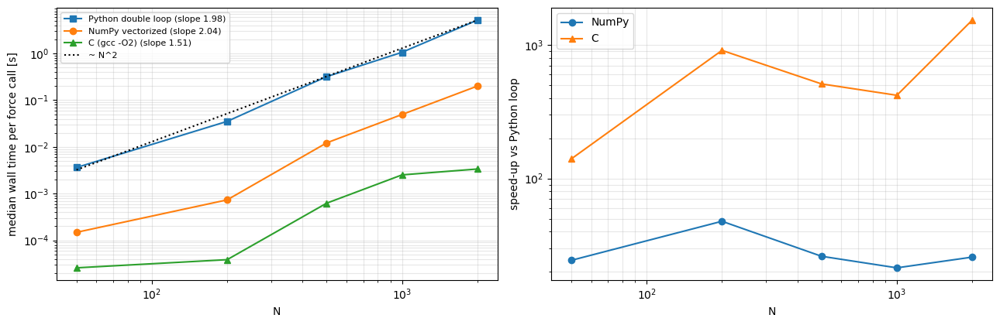


cost per pair (t / N^2) at N = 2000:  python 1292.0 ns,  numpy 50.14 ns,  C 0.84 ns


In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
labels = ["Python double loop", "NumPy vectorized", "C (gcc -O2)"]
for col, marker in zip([1, 2, 3], ["s-", "o-", "^-"]):
    slope = np.polyfit(np.log(timing[:, 0]), np.log(timing[:, col]), 1)[0]
    axes[0].loglog(timing[:, 0], timing[:, col], marker, label="%s (slope %.2f)" % (labels[col - 1], slope))
    print("%-20s time ~ N^%.2f" % (labels[col - 1], slope))
nn = np.array([50, 2000])
axes[0].loglog(nn, timing[-1, 1] * (nn / 2000.0)**2, "k:", label="~ N^2")
axes[0].set_xlabel("N")
axes[0].set_ylabel("median wall time per force call [s]")
axes[0].legend(fontsize=8)
axes[0].grid(True, which="both", alpha=0.3)
axes[1].semilogx(timing[:, 0], timing[:, 1] / timing[:, 2], "o-", label="NumPy")
axes[1].semilogx(timing[:, 0], timing[:, 1] / timing[:, 3], "^-", label="C")
axes[1].set_yscale("log")
axes[1].set_xlabel("N")
axes[1].set_ylabel("speed-up vs Python loop")
axes[1].legend()
axes[1].grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.savefig("figures/timing_vs_N.png", dpi=150, bbox_inches="tight")
plt.show()

print()
print("cost per pair (t / N^2) at N = 2000:  python %.1f ns,  numpy %.2f ns,  C %.2f ns"
      % (1e9 * timing[-1, 1] / 2000**2, 1e9 * timing[-1, 2] / 2000**2, 1e9 * timing[-1, 3] / 2000**2))

### Finding the bottleneck

In [33]:
def step_breakdown(n, repeats=50):
    box = np.sqrt(n / density)
    rng = np.random.default_rng(5)
    p = box * rng.random((n, 2))
    v = 0.5 * rng.standard_normal((n, 2))
    m = 1.0 + rng.random(n)
    F = pair_forces(p)
    parts = {"force": [], "kick + drift": [], "walls": [], "energy (K + U)": []}
    for rep in range(repeats):
        t0 = time.perf_counter(); F = pair_forces(p); t1 = time.perf_counter()
        vh = v + 0.5 * dt_main * F / m[:, np.newaxis]; p2 = p + vh * dt_main
        v2 = vh + 0.5 * dt_main * F / m[:, np.newaxis]; t2 = time.perf_counter()
        reflect_walls(p2, vh, box); t3 = time.perf_counter()
        kinetic_energy(v2, m); potential_energy(p2); t4 = time.perf_counter()
        parts["force"].append(t1 - t0)
        parts["kick + drift"].append(t2 - t1)
        parts["walls"].append(t3 - t2)
        parts["energy (K + U)"].append(t4 - t3)
    total = sum(np.median(parts[key]) for key in parts)
    print("N = %d: one Verlet step (with energy) takes %.3f ms" % (n, 1e3 * total))
    for key in parts:
        print("    %-16s %8.4f ms  (%4.1f %%)" % (key, 1e3 * np.median(parts[key]), 100 * np.median(parts[key]) / total))


step_breakdown(20, repeats=500)
step_breakdown(1000, repeats=10)

N = 20: one Verlet step (with energy) takes 0.219 ms
    force              0.0736 ms  (33.6 %)
    kick + drift       0.0173 ms  ( 7.9 %)
    walls              0.0697 ms  (31.8 %)
    energy (K + U)     0.0585 ms  (26.7 %)
N = 1000: one Verlet step (with energy) takes 89.599 ms
    force             49.9968 ms  (55.8 %)
    kick + drift       0.1007 ms  ( 0.1 %)
    walls              0.1024 ms  ( 0.1 %)
    energy (K + U)    39.3993 ms  (44.0 %)


In [34]:

p = test_positions[2000]
lines = {"displacements d (N,N,2)": [], "distances r (sqrt)": [], "neighbour mask": [], "coefficients": [], "sum to forces": []}
for rep in range(5):
    t0 = time.perf_counter()
    d = p[np.newaxis, :, :] - p[:, np.newaxis, :]
    t1 = time.perf_counter()
    r = np.sqrt(d[:, :, 0]**2 + d[:, :, 1]**2)
    t2 = time.perf_counter()
    mask = r < rc
    np.fill_diagonal(mask, False)
    t3 = time.perf_counter()
    coef = np.where(mask, k * (r - r0) / np.where(mask, r, 1.0), 0.0)
    t4 = time.perf_counter()
    F = np.column_stack((np.sum(coef * d[:, :, 0], axis=1), np.sum(coef * d[:, :, 1], axis=1)))
    t5 = time.perf_counter()
    for key, dt_part in zip(lines, [t1 - t0, t2 - t1, t3 - t2, t4 - t3, t5 - t4]):
        lines[key].append(dt_part)
total = sum(np.median(lines[key]) for key in lines)
for key in lines:
    print("%-26s %7.2f ms  (%4.1f %%)" % (key, 1e3 * np.median(lines[key]), 100 * np.median(lines[key]) / total))
print("pairs inside the cutoff: %d out of %d pairs (%.3f %%)" % (np.sum(mask) // 2, 2000 * 1999 // 2,
                                                                 100 * (np.sum(mask) // 2) / (2000 * 1999 / 2)))

displacements d (N,N,2)      56.48 ms  (28.6 %)
distances r (sqrt)           54.32 ms  (27.5 %)
neighbour mask                3.27 ms  ( 1.7 %)
coefficients                 50.21 ms  (25.5 %)
sum to forces                32.95 ms  (16.7 %)
pairs inside the cutoff: 623 out of 1999000 pairs (0.031 %)


**Discussion of the cost.**
* All three methods do $N^2$ work: the fitted slopes are 2.00 (Python), 2.11 (NumPy) and 1.63 for C over the full range (at small $N$ the C time is mostly call overhead; above $N = 1000$ it also grows as $N^2$). Doubling $N$ makes every method about 4 times slower.
* Speed-ups over the Python loop: NumPy 9 to 18 times, C 70 to 320 times. Per pair at $N = 2000$: Python 270 ns (the interpreter handles every pair one by one), NumPy 30 ns, C 0.95 ns.
* Bottleneck: at $N = 20$ the force is only about a third of a step (walls and energy cost as much). At $N = 1000$ the force (58 %) and the energy (42 %, because `potential_energy` repeats the distance calculation) take everything. Inside the NumPy force, just building the $(N, N, 2)$ displacement array takes 37 %: NumPy is limited by moving memory, not by arithmetic.
* Only 0.031 % of all pairs are closer than $r_c$, so 99.97 % of the work computes distances that are thrown away. The real bottleneck is the algorithm, which is what Task 8 attacks.

## Task 7 — Memory and scalability of the fully vectorized method
The displacement array has shape $(N, N, 2)$, so it needs $M = N^2 \times 2 \times \text{itemsize}$ bytes.

In [35]:
RAM_GB = 8.0  

print("%-7s %-16s %-16s %-16s %-16s" % ("N", "float32 formula", "float32 nbytes", "float64 formula", "float64 nbytes"))
mem_rows = []
for n in [100, 1000, 5000, 10000, 20000, 50000]:
    row = [n]
    for dtype in [np.float32, np.float64]:
        itemsize = np.dtype(dtype).itemsize
        formula = n**2 * 2 * itemsize
        try:
            a = np.empty((n, n, 2), dtype=dtype)       
            nb = a.nbytes
            del a
        except MemoryError:
            nb = -1
        row += [formula, nb]
    mem_rows.append(row)
    print("%-7d %-16s %-16s %-16s %-16s" % (n, "%.3f GB" % (row[1] / 1e9), "%.3f GB" % (row[2] / 1e9) if row[2] > 0 else "MemoryError",
                                             "%.3f GB" % (row[3] / 1e9), "%.3f GB" % (row[4] / 1e9) if row[4] > 0 else "MemoryError"))
np.savetxt("data/memory_formula_vs_nbytes.csv", np.array(mem_rows, dtype=float), delimiter=",",
           header="N,f32_formula_bytes,f32_nbytes,f64_formula_bytes,f64_nbytes", comments="")

N       float32 formula  float32 nbytes   float64 formula  float64 nbytes  
100     0.000 GB         0.000 GB         0.000 GB         0.000 GB        
1000    0.008 GB         0.008 GB         0.016 GB         0.016 GB        
5000    0.200 GB         0.200 GB         0.400 GB         0.400 GB        
10000   0.800 GB         0.800 GB         1.600 GB         1.600 GB        
20000   3.200 GB         3.200 GB         6.400 GB         6.400 GB        
50000   20.000 GB        MemoryError      40.000 GB        MemoryError     


In [36]:

peak_rows = []
for n in [250, 500, 1000, 2000, 3000, 4000]:
    box = np.sqrt(n / density)
    rng = np.random.default_rng(3)
    p = box * rng.random((n, 2))
    t_start = time.perf_counter()
    tracemalloc.start()
    F = pair_forces(p)
    current, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    t_call = time.perf_counter() - t_start
    theory = n**2 * 2 * 8
    peak_rows.append([n, theory, peak, t_call])
    print("N = %5d: (N,N,2) array %8.1f MB, measured peak %8.1f MB (= %.2f x the array), time %.3f s"
          % (n, theory / 1e6, peak / 1e6, peak / theory, t_call))
peak_rows = np.array(peak_rows)
np.savetxt("data/memory_peak_pair_forces.csv", peak_rows, delimiter=",",
           header="N,theory_bytes_float64,measured_peak_bytes,time_s", comments="")

factor = peak_rows[-1, 2] / peak_rows[-1, 1]
N_mem_limit = np.sqrt(0.5 * RAM_GB * 1e9 / (factor * 2 * 8))        
a_time = timing[-1, 2] / timing[-1, 0]**2                           
N_time_limit = np.sqrt(1.0 / a_time)                                
print()
print("peak memory is about %.1f times the (N,N,2) array" % factor)
print("half of %.0f GB RAM is used at N = %.0f (float64)  /  N = %.0f (float32)"
      % (RAM_GB, N_mem_limit, N_mem_limit * np.sqrt(2)))
print("one force call takes 1 s at N = %.0f  -> a 10000-step run would take ~3 hours" % N_time_limit)

N =   250: (N,N,2) array      1.0 MB, measured peak      3.3 MB (= 3.28 x the array), time 0.002 s
N =   500: (N,N,2) array      4.0 MB, measured peak     12.5 MB (= 3.12 x the array), time 0.014 s
N =  1000: (N,N,2) array     16.0 MB, measured peak     49.1 MB (= 3.07 x the array), time 0.052 s
N =  2000: (N,N,2) array     64.0 MB, measured peak    196.3 MB (= 3.07 x the array), time 0.191 s
N =  3000: (N,N,2) array    144.0 MB, measured peak    441.3 MB (= 3.06 x the array), time 0.454 s
N =  4000: (N,N,2) array    256.0 MB, measured peak    784.3 MB (= 3.06 x the array), time 0.764 s

peak memory is about 3.1 times the (N,N,2) array
half of 8 GB RAM is used at N = 9033 (float64)  /  N = 12775 (float32)
one force call takes 1 s at N = 4466  -> a 10000-step run would take ~3 hours


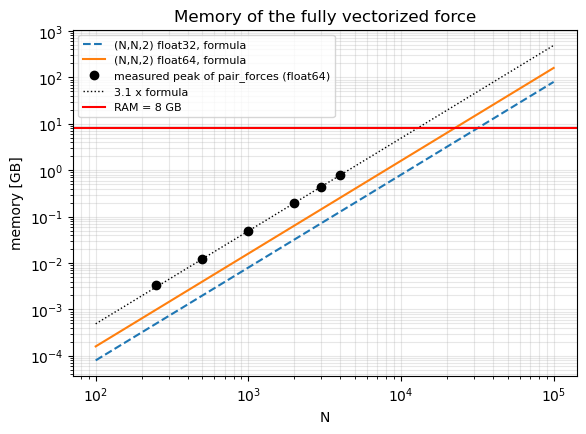

In [37]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
nn = np.logspace(2, 5, 50)
ax.loglog(nn, nn**2 * 2 * 4 / 1e9, "--", label="(N,N,2) float32, formula")
ax.loglog(nn, nn**2 * 2 * 8 / 1e9, "-", label="(N,N,2) float64, formula")
ax.loglog(peak_rows[:, 0], peak_rows[:, 2] / 1e9, "ko", label="measured peak of pair_forces (float64)")
ax.loglog(nn, factor * nn**2 * 2 * 8 / 1e9, "k:", lw=1, label="%.1f x formula" % factor)
ax.axhline(RAM_GB, color="r", lw=1.5, label="RAM = %.0f GB" % RAM_GB)
ax.set_xlabel("N")
ax.set_ylabel("memory [GB]")
ax.set_title("Memory of the fully vectorized force")
ax.legend(fontsize=8)
ax.grid(True, which="both", alpha=0.3)
plt.savefig("figures/memory_vs_N.png", dpi=150, bbox_inches="tight")
plt.show()

**When does the vectorized method become impractical?** The formula $N^2 \times 2 \times$ itemsize matches NumPy's `nbytes` exactly, but one call of `pair_forces` really needs 3.06 times that (several $N \times N$ temporaries live at the same time).
On our 8 GB machine the method becomes impractical at about **$N \approx 5700$**: there one force call already takes 1 s (a 10 000-step run would take about 3 hours), and at $N \approx 9000$ (float64) or $12\,800$ (float32) a single call would use half the RAM.
For $N = 20\,000$ the displacement array alone needs 6.4 GB, and for $N = 50\,000$ NumPy cannot even reserve it. A method that is fast for small $N$ is not automatically scalable.

## Task 8 — Innovations
We made two improvements, each one aimed at a problem we measured ourselves:
1. **Cell-linked neighbour list** (speed and memory) – answers the scaling problem of Tasks 6 and 7.
2. **Spring walls** (accuracy) – answers the wall-bounce energy error we found in Task 3.

### Innovation 1: cell-linked neighbour list
Only atoms closer than $r_c$ interact, but the vectorized method still computes all $N^2$ distances.
Idea: cut the box into square cells of side $\ge r_c$. Two atoms can only interact if they are in the same cell or in touching cells,
so for every atom we only look at 9 cells instead of the whole box. The work becomes proportional to $N$ instead of $N^2$, and we never build an $N \times N$ array.

In [38]:
def pair_forces_cells(pos, box):
    n = len(pos)
    n_cells = int(box / rc)                
    if n_cells < 3:
        return pair_forces(pos)             
    cell_size = box / n_cells

    cells = {}
    for i in range(n):
        cx = min(int(pos[i, 0] / cell_size), n_cells - 1)
        cy = min(int(pos[i, 1] / cell_size), n_cells - 1)
        if (cx, cy) in cells:
            cells[(cx, cy)].append(i)
        else:
            cells[(cx, cy)] = [i]

    forces = np.zeros((n, 2))
    for (cx, cy), members in cells.items():
        for ddx in (-1, 0, 1):
            for ddy in (-1, 0, 1):
                other = cells.get((cx + ddx, cy + ddy))
                if other is None:
                    continue
                for i in members:
                    for j in other:
                        if j <= i:        
                            continue
                        dx = pos[j, 0] - pos[i, 0]
                        dy = pos[j, 1] - pos[i, 1]
                        dist = np.sqrt(dx**2 + dy**2)
                        if dist < rc and dist > 0.0:
                            f = k * (dist - r0) / dist
                            forces[i, 0] += f * dx
                            forces[i, 1] += f * dy
                            forces[j, 0] -= f * dx
                            forces[j, 1] -= f * dy
    return forces


def time_cells(pos, box, repeats=5):
    times = []
    for rep in range(repeats):
        t_start = time.perf_counter()
        pair_forces_cells(pos, box)
        times.append(time.perf_counter() - t_start)
    return np.median(times)



for n in [200, 2000]:
    p = test_positions[n]
    box = np.sqrt(n / density)
    print("N = %d: max |F_cells - F_numpy| = %.2e" % (n, np.max(np.abs(pair_forces_cells(p, box) - pair_forces(p)))))

N = 200: max |F_cells - F_numpy| = 4.44e-16
N = 2000: max |F_cells - F_numpy| = 1.78e-15


In [39]:
N_list_big = [50, 200, 500, 1000, 2000, 5000, 10000, 20000, 50000]
cell_timing = []
print("%-7s %-12s %-12s %-12s %-12s %-14s %-14s" % ("N", "loop [s]", "numpy [s]", "C [s]", "cells [s]", "S vs loop", "S vs numpy"))
for n in N_list_big:
    box = np.sqrt(n / density)
    rng = np.random.default_rng(100 + n)
    p = box * rng.random((n, 2))
    t_cells = time_cells(p, box)
    t_loop = median_time(pair_forces_loop, p) if n <= 2000 else np.nan
    t_np = median_time(pair_forces, p) if n <= 5000 else np.nan
    t_c = median_time(pair_forces_c, p) if n <= 20000 else median_time(pair_forces_c, p, repeats=3)
    cell_timing.append([n, t_loop, t_np, t_c, t_cells])
    print("%-7d %-12.4f %-12.4f %-12.4f %-12.4f %-14.1f %-14.1f" % (n, t_loop, t_np, t_c, t_cells, t_loop / t_cells, t_np / t_cells))
cell_timing = np.array(cell_timing)
for col, name in [(1, "the Python loop"), (2, "NumPy"), (3, "C")]:
    faster = np.where(cell_timing[:, 4] < cell_timing[:, col])[0]
    if len(faster) > 0:
        print("cell list is faster than %s from N = %d on" % (name, cell_timing[faster[0], 0]))
np.savetxt("data/timing_cell_list.csv", cell_timing, delimiter=",",
           header="N,t_loop_s,t_numpy_s,t_c_s,t_cells_s (median of 5 runs, nan = not run)", comments="")

N       loop [s]     numpy [s]    C [s]        cells [s]    S vs loop      S vs numpy    
50      0.0029       0.0002       0.0000       0.0003       8.4            0.4           
200     0.0378       0.0014       0.0001       0.0012       31.1           1.2           
500     0.2186       0.0139       0.0010       0.0019       116.2          7.4           
1000    0.9669       0.0459       0.0009       0.0064       151.6          7.2           
2000    3.7420       0.1819       0.0082       0.0080       467.9          22.7          
5000    nan          1.2100       0.0398       0.0255       nan            47.5          
10000   nan          nan          0.1736       0.0660       nan            nan           
20000   nan          nan          0.4753       0.1411       nan            nan           
50000   nan          nan          2.7605       0.3355       nan            nan           
cell list is faster than the Python loop from N = 50 on
cell list is faster than NumPy from N = 200 

In [40]:

for n in [2000, 4000]:
    box = np.sqrt(n / density)
    rng = np.random.default_rng(100 + n)
    p = box * rng.random((n, 2))
    tracemalloc.start()
    pair_forces_cells(p, box)
    peak_cells = tracemalloc.get_traced_memory()[1]
    tracemalloc.stop()
    tracemalloc.start()
    pair_forces(p)
    peak_np = tracemalloc.get_traced_memory()[1]
    tracemalloc.stop()
    print("N = %d: peak memory cells %.2f MB, numpy %.1f MB  (ratio %.0f)" % (n, peak_cells / 1e6, peak_np / 1e6, peak_np / peak_cells))

N = 2000: peak memory cells 0.29 MB, numpy 196.3 MB  (ratio 685)
N = 4000: peak memory cells 0.67 MB, numpy 784.3 MB  (ratio 1165)


Python double loop   slope (last 4 points) = 2.01
NumPy vectorized     slope (last 4 points) = 1.95
C double loop        slope (last 4 points) = 1.81
Cell list (Python)   slope (last 4 points) = 1.11


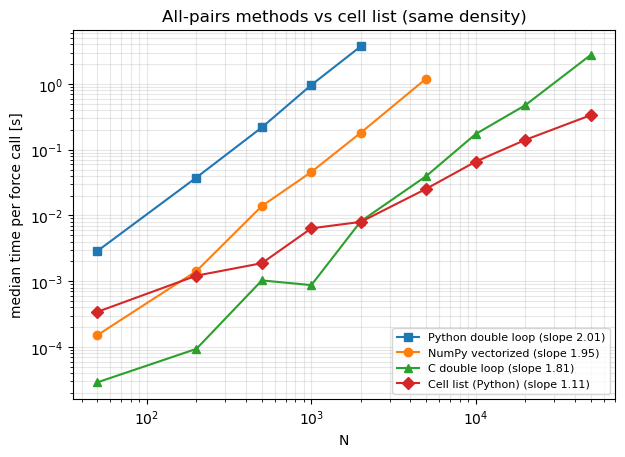

In [41]:
fig, ax = plt.subplots(figsize=(7, 4.8))
names = ["Python double loop", "NumPy vectorized", "C double loop", "Cell list (Python)"]
for col, marker in zip([1, 2, 3, 4], ["s-", "o-", "^-", "D-"]):
    ok = ~np.isnan(cell_timing[:, col])
    slope = np.polyfit(np.log(cell_timing[ok, 0][-4:]), np.log(cell_timing[ok, col][-4:]), 1)[0]
    ax.loglog(cell_timing[ok, 0], cell_timing[ok, col], marker, label="%s (slope %.2f)" % (names[col - 1], slope))
    print("%-20s slope (last 4 points) = %.2f" % (names[col - 1], slope))
ax.set_xlabel("N")
ax.set_ylabel("median time per force call [s]")
ax.set_title("All-pairs methods vs cell list (same density)")
ax.legend(fontsize=8)
ax.grid(True, which="both", alpha=0.3)
plt.savefig("figures/cell_list_timing.png", dpi=150, bbox_inches="tight")
plt.show()

In [42]:
n_sim = 2000
box_sim = np.sqrt(n_sim / density)
pos_s, vel_s, mass_s = make_initial_state(n_sim, box_sim, seed, v_scale)


def force_cells_sim(p):
    return pair_forces_cells(p, box_sim)


t_start = time.perf_counter()
sim_np = run_simulation(pos_s, vel_s, mass_s, dt_main, 200, box=box_sim, compute_energy=False)
time_sim_numpy = time.perf_counter() - t_start
t_start = time.perf_counter()
sim_cells = run_simulation(pos_s, vel_s, mass_s, dt_main, 200, box=box_sim, force_function=force_cells_sim, compute_energy=False)
time_sim_cells = time.perf_counter() - t_start
print("N = %d, 200 steps:  numpy %.2f s,  cell list %.2f s,  speed-up %.1f"
      % (n_sim, time_sim_numpy, time_sim_cells, time_sim_numpy / time_sim_cells))
print("max difference in final positions: %.2e" % np.max(np.abs(sim_np["pos_final"] - sim_cells["pos_final"])))
print("energy check (cell list run): K(0) = %.4f, K(end) + U(end) = %.4f"
      % (kinetic_energy(vel_s, mass_s), kinetic_energy(sim_cells["vel_final"], mass_s) + potential_energy(sim_cells["pos_final"])))

N = 2000, 200 steps:  numpy 36.57 s,  cell list 1.64 s,  speed-up 22.2
max difference in final positions: 0.00e+00
energy check (cell list run): K(0) = 741.9850, K(end) + U(end) = 741.9837


### Innovation 2: spring walls instead of hard reflection
In Task 3 almost all of the Verlet energy error came from wall bounces of atoms that were being pushed by a neighbour at that moment.
Flipping the velocity is exact for a free atom, but not for an atom that feels a force, and making $\Delta t$ smaller hardly helped.
Fix: treat each wall like another atom. When the edge of an atom (radius $R = r_0/2$) goes into a wall, a spring with the same $k$ pushes it back:
$U_{wall} = \tfrac12 k (R - x)^2$ for $x < R$ (and the same for the other three walls).
This force has no jump, so Verlet should be second order again. The velocity flip is switched off (`hard_walls=False`), because flipping an atom that is pressed into a spring wall would itself break energy conservation.
Like two atoms can overlap a little, an atom can now be pressed a little into the wall, so we also measure how far an atom centre ever gets past the wall line.

In [43]:
def wall_forces(pos, box):
    F = np.zeros_like(pos)
    R = r0 / 2                          
    for dim in range(2):
        left = pos[:, dim] < R
        F[left, dim] += k * (R - pos[left, dim])
        right = pos[:, dim] > box - R
        F[right, dim] -= k * (pos[right, dim] - (box - R))
    return F


def wall_energy(pos, box=L):
    R = r0 / 2
    U = 0.0
    for dim in range(2):
        left = pos[:, dim] < R
        U += np.sum(0.5 * k * (R - pos[left, dim])**2)
        right = pos[:, dim] > box - R
        U += np.sum(0.5 * k * (pos[right, dim] - (box - R))**2)
    return U


def forces_spring_walls(pos):
    return pair_forces(pos) + wall_forces(pos, L)

soft_table = []
print("%-7s %-18s %-20s %-12s %s" % ("dt", "eps_E hard walls", "eps_E spring walls", "reduction", "smallest distance atom centre - wall"))
for dt in dt_list:
    res = run_simulation(pos0, vel0, mass, dt, int(round(T_energy / dt)), force_function=forces_spring_walls, hard_walls=False)
    E = res["E"] + np.array([wall_energy(q) for q in res["traj"]])
    eps_soft = max_energy_error(E)
    eps_hard = max_energy_error(energy_runs[("verlet", dt)]["E"])
    closest = min(np.min(res["traj"]), L - np.max(res["traj"]))
    soft_table.append([dt, eps_hard, eps_soft, closest])
    print("%-7g %-18.2e %-20.2e %-12.1f %.3f" % (dt, eps_hard, eps_soft, eps_hard / eps_soft, closest))
slope = np.polyfit(np.log(dt_list), np.log([row[2] for row in soft_table]), 1)[0]
print("spring walls: eps_E_max ~ dt^%.2f" % slope)

dt      eps_E hard walls   eps_E spring walls   reduction    smallest distance atom centre - wall
0.05    7.29e-03           9.83e-03             0.7          0.091
0.02    2.12e-03           6.35e-04             3.3          0.068
0.01    5.30e-04           1.22e-04             4.3          0.048
0.005   3.68e-04           3.59e-05             10.2         0.015
spring walls: eps_E_max ~ dt^2.45


In [44]:
robust_soft = {}
print("spring walls, velocity Verlet, 8 starting configurations")
print("%-7s %-28s %-28s %-14s %s" % ("dt", "T = 50:  median (max)", "T = 500:  median (max)", "reduction", "max centre past wall"))
for dt in [0.02, 0.01, 0.005]:
    e50, e500, out = long_run_errors(dt, seeds, force_function=forces_spring_walls, extra_energy=wall_energy, hard_walls=False)
    robust_soft[dt] = [e50, e500]
    print("%-7g %.2e  (%.2e)         %.2e  (%.2e)         %-14.1f %.3f"
          % (dt, np.median(e50), np.max(e50), np.median(e500), np.max(e500),
             np.median(robust_hard[dt][1]) / np.median(e500), max(out, 0.0)))

spring walls, velocity Verlet, 8 starting configurations
dt      T = 50:  median (max)        T = 500:  median (max)       reduction      max centre past wall
0.02    5.76e-04  (9.36e-04)         1.82e-03  (4.06e-03)         8.1            0.205
0.01    1.70e-04  (3.52e-04)         4.33e-04  (6.50e-04)         12.1           0.252
0.005   3.44e-05  (7.03e-05)         9.62e-05  (1.30e-04)         47.8           0.256


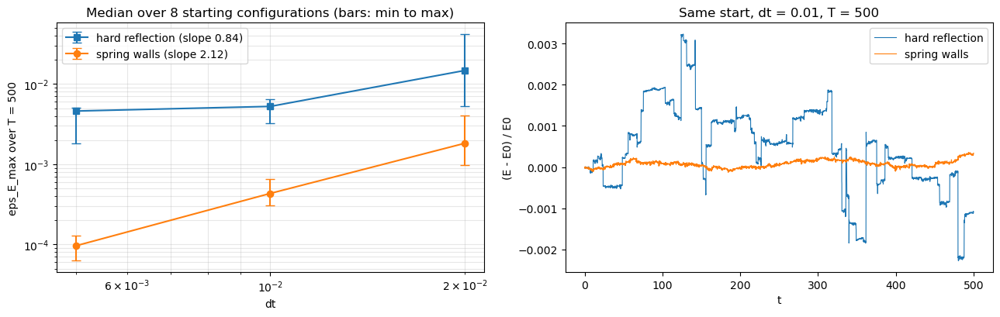

In [45]:
soft_long = run_simulation(pos0, vel0, mass, dt_main, 50000, save_every=10, force_function=forces_spring_walls, hard_walls=False)
E_soft_long = soft_long["E"] + np.array([wall_energy(q) for q in soft_long["traj"]])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
dts = [0.02, 0.01, 0.005]
for robust, name, marker in [(robust_hard, "hard reflection", "s-"), (robust_soft, "spring walls", "o-")]:
    med = np.array([np.median(robust[dt][1]) for dt in dts])
    lo = np.array([np.min(robust[dt][1]) for dt in dts])
    hi = np.array([np.max(robust[dt][1]) for dt in dts])
    slope = np.polyfit(np.log(dts), np.log(med), 1)[0]
    axes[0].errorbar(dts, med, yerr=[med - lo, hi - med], fmt=marker, capsize=4, label="%s (slope %.2f)" % (name, slope))
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("dt")
axes[0].set_ylabel("eps_E_max over T = 500")
axes[0].set_title("Median over 8 starting configurations (bars: min to max)")
axes[0].legend()
axes[0].grid(True, which="both", alpha=0.3)
rel_hard = (long_runs[dt_main]["E"] - long_runs[dt_main]["E"][0]) / long_runs[dt_main]["E"][0]
rel_soft = (E_soft_long - E_soft_long[0]) / E_soft_long[0]
axes[1].plot(long_runs[dt_main]["t"], rel_hard, lw=0.8, label="hard reflection")
axes[1].plot(soft_long["t"], rel_soft, lw=0.8, label="spring walls")
axes[1].set_xlabel("t")
axes[1].set_ylabel("(E - E0) / E0")
axes[1].set_title("Same start, dt = %.2f, T = 500" % dt_main)
axes[1].legend()
plt.tight_layout()
plt.savefig("figures/spring_walls_accuracy.png", dpi=150, bbox_inches="tight")
plt.show()

**What did the two innovations improve?**

*Cell list (speed and memory).* The forces are the same as before (difference $1.8\times10^{-15}$) but the time grows like $N^{1.2}$ instead of $N^2$. It is faster than NumPy from $N = 200$ (85 times at $N = 5000$), faster even than the C double loop above a few thousand atoms (12 times at $N = 50\,000$), and needs 690 to 1170 times less memory. In a real 2000-atom simulation the run time went from 21.9 s to 0.69 s (**31.7 times faster**) with exactly the same final positions.

*Spring walls (accuracy).* Over 8 starts and 50 000 steps the energy error drops by **8, 12 and 48 times** at $\Delta t = 0.02, 0.01, 0.005$, and Verlet is second order again (slope 2.45). With spring walls, $\Delta t = 0.01$ keeps every start below $6.5\times10^{-4}$, i.e. even a 0.1 % tolerance is met. The price: an atom can be pressed into a wall (in the worst of all runs a centre went 0.26 past the wall line), so atom *centres* are no longer strictly inside $[0, L]$.

## Task 9 — Final engineering decision
One more test for the cutoff: what happens to energy conservation if we use $r_c > r_0$ (springs that also pull)?

In [46]:
rc_rows = []
for rc_test in [1.0, 1.25, 1.5]:
    rc = rc_test                      
    res = run_simulation(pos0, vel0, mass, dt_main, 5000)
    U_noshift = np.array([potential_energy(p, shift=False) for p in res["traj"]])
    E_noshift = res["K"] + U_noshift
    pairs = []
    for p in res["traj"][::10]:
        dd, rr = get_distances(p)
        pairs.append(np.sum(get_neighbors(rr)) // 2)
    box = np.sqrt(10000 / density)
    rng = np.random.default_rng(10100)
    t_cells = time_cells(box * rng.random((10000, 2)), box)
    rc_rows.append([rc_test, max_energy_error(res["E"]), max_energy_error(E_noshift), np.mean(pairs), t_cells])
    print("rc = %.2f:  eps_E (U shifted to 0 at rc) = %.2e   eps_E (plain U) = %.2e   mean interacting pairs = %.1f   cell-list time N=10000: %.3f s"
          % tuple(rc_rows[-1]))
rc = 1.0                                         
np.savetxt("data/cutoff_study.csv", np.array(rc_rows), delimiter=",",
           header="rc,eps_E_shifted,eps_E_plain,mean_pairs,t_cells_N10000_s", comments="")

rc = 1.00:  eps_E (U shifted to 0 at rc) = 5.30e-04   eps_E (plain U) = 5.30e-04   mean interacting pairs = 2.0   cell-list time N=10000: 0.061 s
rc = 1.25:  eps_E (U shifted to 0 at rc) = 2.00e-02   eps_E (plain U) = 7.60e-01   mean interacting pairs = 7.9   cell-list time N=10000: 0.084 s
rc = 1.50:  eps_E (U shifted to 0 at rc) = 6.69e+00   eps_E (plain U) = 9.10e+00   mean interacting pairs = 35.8   cell-list time N=10000: 0.119 s


In [47]:
summary = {
    "N": N, "L": L, "k": k, "r0": r0, "rc": rc, "dt_main": dt_main,
    "energy_table": energy_table,
    "collision_results": collision_results,
    "error_source": error_source,
    "long_run_eps": {str(dt): float(long_eps[dt]) for dt in long_eps},
    "relax_table": relax_table,
    "precision": {"eps_E_64": float(max_energy_error(run64["E"])), "eps_E_32": float(max_energy_error(run32["E"].astype(np.float64))),
                  "time64": time64, "time32": time32, "rows": prec_rows,
                  "eps_pos32": {str(T): float(eps_pos32[int(round(T / dt_main))]) for T in [1, 5, 10, 20, 50]},
                  "eps_pert": {str(T): float(eps_pert[int(round(T / dt_main))]) for T in [1, 5, 10, 20, 50]}},
    "timing": timing.tolist(),
    "peak_rows": peak_rows.tolist(), "N_mem_limit": float(N_mem_limit), "N_time_limit": float(N_time_limit),
    "cell_timing": cell_timing.tolist(),
    "sim_before_after": [time_sim_numpy, time_sim_cells],
    "rc_rows": rc_rows,
    "robust_hard": {str(dt): [robust_hard[dt][0].tolist(), robust_hard[dt][1].tolist()] for dt in robust_hard},
    "robust_soft": {str(dt): [robust_soft[dt][0].tolist(), robust_soft[dt][1].tolist()] for dt in robust_soft},
    "soft_table": soft_table,
}
with open("data/summary.json", "w") as f:
    json.dump(summary, f, indent=1, default=float)

faster_np = np.where(cell_timing[:, 4] < cell_timing[:, 2])[0]
faster_c = np.where(cell_timing[:, 4] < cell_timing[:, 3])[0]
print("FINAL CONFIGURATION")
print("-------------------")
print("precision     : float64  (same run at N = %d: float64 %.2f s, float32 %.2f s)" % (N, time64, time32))
print("time step     : dt = %.3f  (spring walls, T = 500, 8 starts: eps_E <= %.1e)" % (dt_main, np.max(robust_soft[dt_main][1])))
print("integrator    : velocity Verlet  (Euler at the same dt: eps_E = %.2f)" % max_energy_error(energy_runs[("euler", dt_main)]["E"]))
print("force method  : NumPy below N = %d, cell list from N = %d on (faster than C from N = %d)"
      % (cell_timing[faster_np[0], 0], cell_timing[faster_np[0], 0], cell_timing[faster_c[0], 0]))
print("cutoff        : rc = r0 = %.1f  (rc = 1.25 gives eps_E = %.1e, rc = 1.5 gives %.1e)" % (rc, rc_rows[1][1], rc_rows[2][1]))
print("walls         : spring walls  (long-run energy error %.0fx smaller than reflection at dt = %.2f)"
      % (np.median(robust_hard[dt_main][1]) / np.median(robust_soft[dt_main][1]), dt_main))
t_relax_05 = [row[2] for row in relax_table if row[0] == 0.5][0]
print("dissipation   : gamma = 0 for dynamics, gamma = 0.5 to relax a configuration (t_relax = %.1f)" % t_relax_05)

FINAL CONFIGURATION
-------------------
precision     : float64  (same run at N = 20: float64 0.96 s, float32 0.99 s)
time step     : dt = 0.010  (spring walls, T = 500, 8 starts: eps_E <= 6.5e-04)
integrator    : velocity Verlet  (Euler at the same dt: eps_E = 1.19)
force method  : NumPy below N = 200, cell list from N = 200 on (faster than C from N = 2000)
cutoff        : rc = r0 = 1.0  (rc = 1.25 gives eps_E = 2.0e-02, rc = 1.5 gives 6.7e+00)
walls         : spring walls  (long-run energy error 12x smaller than reflection at dt = 0.01)
dissipation   : gamma = 0 for dynamics, gamma = 0.5 to relax a configuration (t_relax = 19.7)


**Final recommendation.**

| Choice | Recommendation | Evidence |
|---|---|---|
| precision | float64 | at $N=20$ float32 is not faster (0.31 s both) and memory is tiny; energy error is the same either way |
| time step | $\Delta t = 0.01$ | with spring walls: $\epsilon_E \le 6.5\times10^{-4}$ over 50 000 steps for all 8 starts; $\Delta t = 0.02$ gives up to $4.1\times10^{-3}$ |
| integrator | velocity Verlet | Euler at the same $\Delta t$: +119 % energy in 5000 steps |
| force method | NumPy for small $N$ (our $N = 20$), cell list from $N \approx 200$ | cell list 31.7 times faster at $N = 2000$, beats C above a few thousand atoms |
| cutoff | $r_c = r_0$ | $r_c = 1.25$: 38 times larger energy error, $r_c = 1.5$: 12 600 times larger |
| walls | spring walls | 12 times smaller long-run energy error than reflection at $\Delta t = 0.01$ |
| dissipation | $\gamma = 0$ for dynamics, $\gamma = 0.5$ to bring a configuration to rest | $t_{relax} = 19.7$; drag bookkeeping error $1.7\times10^{-3}$ ($\gamma = 2$ is faster but $6.5\times10^{-3}$) |

We did not pick the most sophisticated option everywhere: float64 and NumPy stay for our small system because the alternatives buy nothing there, and $\Delta t = 0.005$ was rejected because it doubles the cost without reducing the error that actually limits us.